# SwiftLog Logistics: Intelligent Logistics Prediction & Supply Chain Optimization
**Week 5, Machine Learning Track (Mission ML05)** | AnalystLab Africa Experience Lab | Gyimah Ramsey Opoku

SwiftLog Logistics Limited is a fictional Nigerian logistics company. This notebook builds and evaluates supervised
models on its (synthetic) operational data, and is written to be re-run top to bottom.

**Contents**
1. Setup, data loading and data audit
2. Cleaning, leakage check and feature engineering (Part 1)
3. Exploratory data analysis for ML (Part 2)
4. Modelling framework and four predictive models (Part 3 and Part 4)
5. Model comparison and selection
6. Interpretation and explainability (Part 5)
7. Business insights (Part 7)
8. Saving artefacts for the app (Part 6) and reports (Part 8)

**A note on honesty before we start.** The first thing the audit shows is that the data behaves like independent random
draws: none of the four problems has a learnable signal that beats a naive baseline. The notebook is built to *measure*
that properly (baselines, cross-validation, confidence intervals, label-shuffle checks) instead of tuning until a number
looks good. Every conclusion below follows from what the numbers actually show.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import json, time
from pathlib import Path
import joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, TimeSeriesSplit,
                                     cross_validate, RandomizedSearchCV, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, mutual_info_classif, mutual_info_regression, f_classif, f_regression
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              RandomForestRegressor, GradientBoostingRegressor)
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier, XGBRegressor
import shap

SEED = 42
np.random.seed(SEED)
ROOT = Path.cwd().parent
DATA, ORIG, PROC = ROOT/'Data', ROOT/'Data'/'Original_Datasets', ROOT/'Data'/'Processed_Datasets'
MODELS, FIGS, ASSETS = ROOT/'Models', ROOT/'Reports'/'Figures', ROOT/'App'/'assets'
for d in (PROC, MODELS, FIGS, ASSETS): d.mkdir(parents=True, exist_ok=True)

NAVY, TEAL, GOLD, GREY, RED = '#101833', '#1f7a8c', '#c9a227', '#8a8f98', '#b5483a'
sns.set_theme(style='whitegrid', context='notebook', palette=[TEAL, NAVY, GOLD, GREY, RED])
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.spines.top': False, 'axes.spines.right': False})

def savefig(name):
    plt.tight_layout(); plt.savefig(FIGS/f'{name}.png', dpi=150, bbox_inches='tight'); plt.show()

print('pandas', pd.__version__, '| numpy', np.__version__)

pandas 3.0.2 | numpy 2.4.4


## 1. Data loading and audit
All eleven files are imported from `Data/Original_Datasets/` and left untouched. Cleaned copies are written to
`Data/Processed_Datasets/`.

In [2]:
NAMES = ['Customers','Orders','Order_Items','Products','Suppliers','Warehouses','Inventory',
         'Shipments','Delivery_Performance','Employees','Returns']
raw = {n: pd.read_csv(ORIG/f'SwiftLog_{n}.csv', encoding='utf-8-sig') for n in NAMES}
dictionary = pd.read_csv(ORIG/'SwiftLog_Data_Dictionary.csv', encoding='utf-8-sig')

audit = pd.DataFrame([dict(dataset=n, rows=len(d), columns=d.shape[1], key=d.columns[0],
                           duplicate_keys=int(d[d.columns[0]].duplicated().sum()),
                           missing_cells=int(d.isna().sum().sum()), duplicate_rows=int(d.duplicated().sum()))
                      for n, d in raw.items()])
audit

,dataset,rows,columns,key,duplicate_keys,missing_cells,duplicate_rows
0,Customers,1000,3,CustomerID,0,0,0
1,Orders,5000,4,OrderID,0,0,0
2,Order_Items,15000,4,OrderItemID,0,0,0
3,Products,250,3,ProductID,0,0,0
4,Suppliers,150,2,SupplierID,0,0,0
5,Warehouses,15,2,WarehouseID,0,0,0
6,Inventory,4000,3,WarehouseID,3985,0,3
7,Shipments,5000,4,ShipmentID,0,0,0
8,Delivery_Performance,5000,3,ShipmentID,0,0,0
9,Employees,200,2,EmployeeID,0,0,0


In [3]:
print('Data dictionary supplied with the brief:'); display(dictionary)
print('\nColumns per table:')
for n, d in raw.items(): print(f'  {n:<22}', list(d.columns))

Data dictionary supplied with the brief:


,File,Description
0,SwiftLog_Inventory.csv,Dataset
1,SwiftLog_Products.csv,Dataset
2,SwiftLog_Order_Items.csv,Dataset
3,SwiftLog_Warehouses.csv,Dataset
4,SwiftLog_Orders.csv,Dataset
5,SwiftLog_Customers.csv,Dataset
6,SwiftLog_Delivery_Performance.csv,Dataset
7,SwiftLog_Employees.csv,Dataset
8,SwiftLog_Shipments.csv,Dataset
9,SwiftLog_Suppliers.csv,Dataset



Columns per table:
  Customers              ['CustomerID', 'CustomerName', 'City']
  Orders                 ['OrderID', 'CustomerID', 'OrderDate', 'Status']
  Order_Items            ['OrderItemID', 'OrderID', 'ProductID', 'Quantity']
  Products               ['ProductID', 'Category', 'UnitPrice']
  Suppliers              ['SupplierID', 'SupplierName']
  Warehouses             ['WarehouseID', 'Location']
  Inventory              ['WarehouseID', 'ProductID', 'Stock']
  Shipments              ['ShipmentID', 'OrderID', 'WarehouseID', 'DelayDays']
  Delivery_Performance   ['ShipmentID', 'Status', 'DelayDays']
  Employees              ['EmployeeID', 'WarehouseID']
  Returns                ['ReturnID', 'OrderID', 'Reason']


**Audit notes.** No missing cells and no duplicate rows. The supplied data dictionary only says "Dataset" for every file, so
column meaning is taken from the column names and the brief. `Returns.OrderID` repeats (some orders have more than one return
row), and `Shipments` and `Delivery_Performance` share a key. The next cells check the relationships between tables.

In [4]:
o, s, dp, oi, p, rt = raw['Orders'], raw['Shipments'], raw['Delivery_Performance'], raw['Order_Items'], raw['Products'], raw['Returns']

checks = {
 'Orders.CustomerID in Customers':      o.CustomerID.isin(raw['Customers'].CustomerID).mean(),
 'Shipments.OrderID in Orders':         s.OrderID.isin(o.OrderID).mean(),
 'Shipments.WarehouseID in Warehouses': s.WarehouseID.isin(raw['Warehouses'].WarehouseID).mean(),
 'Order_Items.OrderID in Orders':       oi.OrderID.isin(o.OrderID).mean(),
 'Order_Items.ProductID in Products':   oi.ProductID.isin(p.ProductID).mean(),
 'Inventory.ProductID in Products':     raw['Inventory'].ProductID.isin(p.ProductID).mean(),
 'Returns.OrderID in Orders':           rt.OrderID.isin(o.OrderID).mean(),
 'Employees.WarehouseID in Warehouses': raw['Employees'].WarehouseID.isin(raw['Warehouses'].WarehouseID).mean(),
}
print(pd.Series(checks).map('{:.1%}'.format).to_string())

print('\nOne shipment per order?              ', s.OrderID.is_unique, '| orders with a shipment:', f'{o.OrderID.isin(s.OrderID).mean():.0%}')
print('Orders with NO line items:            ', int((~o.OrderID.isin(oi.OrderID)).sum()))
print('Orders with more than one return row: ', int(rt.OrderID.duplicated().sum()))
oo = o.assign(returned=o.OrderID.isin(rt.OrderID))
print('Share of CANCELLED orders that have a return:', f"{oo[oo.Status=='Cancelled'].returned.mean():.1%}", '(a data-quality quirk)')
print('Is any table linked to Suppliers?     ', any('SupplierID' in d.columns for n, d in raw.items() if n != 'Suppliers'))

Orders.CustomerID in Customers         100.0%
Shipments.OrderID in Orders            100.0%
Shipments.WarehouseID in Warehouses    100.0%
Order_Items.OrderID in Orders          100.0%
Order_Items.ProductID in Products      100.0%
Inventory.ProductID in Products        100.0%
Returns.OrderID in Orders              100.0%
Employees.WarehouseID in Warehouses    100.0%

One shipment per order?               True | orders with a shipment: 100%


Orders with NO line items:             236
Orders with more than one return row:  27
Share of CANCELLED orders that have a return: 9.2% (a data-quality quirk)
Is any table linked to Suppliers?      False


**What the integrity checks show**

* Every foreign key resolves (100%), so joins are safe.
* There is **one shipment per order**, so the Orders + Shipments grain is clean.
* **236 orders have no line items.** They are kept, with a `has_items` flag and zero basket features, rather than dropped.
* **Cancelled orders have returns** at about the same rate as delivered ones. That is not realistic, and it is the first sign the
  fields were generated independently. It is documented rather than silently "fixed".
* **No table contains a `SupplierID`.** Suppliers cannot be joined to shipments, products or deliveries, so the brief's
  *Supplier Reliability Prediction* problem is **not buildable from this data**. It is excluded and the reason is reported
  instead of inventing a link.

## 2. Cleaning and the leakage check (Part 1)

In [5]:
clean = {}
for n, d in raw.items():
    d = d.copy()
    for c in d.columns:
        if pd.api.types.is_string_dtype(d[c]): d[c] = d[c].str.strip()
    clean[n] = d

clean['Orders']['OrderDate'] = pd.to_datetime(clean['Orders']['OrderDate'], format='%m/%d/%Y')
orders = clean['Orders']
print('Order dates:', orders.OrderDate.min().date(), 'to', orders.OrderDate.max().date())
print('Orders per month:'); print(orders.groupby(orders.OrderDate.dt.to_period('M')).size().to_string())
for n, d in clean.items(): d.to_csv(PROC/f'SwiftLog_{n}_clean.csv', index=False)
print('\nSaved', len(clean), 'cleaned tables to Data/Processed_Datasets/')

Order dates: 2026-01-01 to 2026-09-08
Orders per month:
OrderDate
2026-01    594
2026-02    577
2026-03    597
2026-04    638
2026-05    612
2026-06    579
2026-07    595
2026-08    654
2026-09    154
Freq: M



Saved 11 cleaned tables to Data/Processed_Datasets/


September 2026 only runs to 8 September, so it is a **partial month** and is excluded wherever a monthly total or trend is used.

### Leakage check: Delivery_Performance vs Shipments
`Delivery_Performance` is meant to be the "delay prediction" table, so it needs checking before anything is built on it.

In [6]:
chk = clean['Shipments'].merge(clean['Delivery_Performance'], on='ShipmentID', suffixes=('_shipment', '_perf'))
print('Same ShipmentID set:                  ', set(clean['Shipments'].ShipmentID) == set(clean['Delivery_Performance'].ShipmentID))
print('DelayDays identical in both tables:   ', f"{(chk.DelayDays_shipment == chk.DelayDays_perf).mean():.0%}")
print('\nDelay days by Delivery_Performance.Status:')
display(pd.crosstab(chk.Status, chk.DelayDays_perf))
assert ((chk.Status == 'Delayed') == (chk.DelayDays_perf >= 3)).all()
print('Status == "Delayed"  <=>  DelayDays >= 3  holds for every row.')

Same ShipmentID set:                   True
DelayDays identical in both tables:    100%

Delay days by Delivery_Performance.Status:


DelayDays_perf,0,1,2,3,4,5,6,7
Status,,,,,,,,
Delayed,0,0,0,605,616,668,664,633
On Time,611,592,611,0,0,0,0,0


Status == "Delayed"  <=>  DelayDays >= 3  holds for every row.


**Finding:** `Delivery_Performance` adds no information. Its `DelayDays` is a copy of the one in `Shipments`, and its `Status`
is a deterministic rule on it (**Delayed means 3 or more days**). A model given either column would score ~100% for a
trivial reason, so both are **used only to define the target** (`delayed = DelayDays >= 3`) and never as features.
This is the single most important modelling decision in the notebook.

## 3. Feature engineering (Part 1)
One row per **order** (5,000 rows), joining Orders + Shipments + Customers + Warehouses + Order_Items + Products +
Inventory + Employees (+ Returns for the return target). Features are grouped by the business idea behind them.

In [7]:
items = clean['Order_Items'].merge(clean['Products'], on='ProductID')
items['line_value'] = items.Quantity * items.UnitPrice

basket = items.groupby('OrderID').agg(n_lines=('OrderItemID','count'), qty=('Quantity','sum'), value=('line_value','sum'),
                                      avg_price=('UnitPrice','mean'), max_price=('UnitPrice','max'),
                                      n_categories=('Category','nunique')).reset_index()
mix = items.pivot_table(index='OrderID', columns='Category', values='line_value', aggfunc='sum', fill_value=0)
mix = mix.div(mix.sum(axis=1), axis=0).add_prefix('share_').reset_index()

inv, emp, wh = clean['Inventory'], clean['Employees'], clean['Warehouses']
ship = clean['Shipments']
wh_prof = (wh.merge(emp.groupby('WarehouseID').size().rename('wh_headcount'), on='WarehouseID', how='left')
             .merge(inv.groupby('WarehouseID').agg(wh_total_stock=('Stock','sum'), wh_stock_lines=('ProductID','nunique'),
                                                   wh_low_stock_share=('Stock', lambda x: (x < 50).mean())).reset_index(), on='WarehouseID', how='left')
             .merge(ship.groupby('WarehouseID').size().rename('wh_shipments'), on='WarehouseID', how='left')
             .rename(columns={'Location': 'wh_location'}))
wh_prof['wh_load'] = wh_prof.wh_shipments / wh_prof.wh_headcount          # shipments handled per employee (utilisation proxy)
wh_prof['wh_stock_per_shipment'] = wh_prof.wh_total_stock / wh_prof.wh_shipments

returned = clean['Returns'].groupby('OrderID').size().rename('n_returns').reset_index()

m = (ship.merge(orders, on='OrderID').merge(clean['Customers'][['CustomerID','City']], on='CustomerID')
         .merge(wh_prof, on='WarehouseID', how='left').merge(basket, on='OrderID', how='left').merge(mix, on='OrderID', how='left')
         .merge(returned, on='OrderID', how='left'))

m['has_items'] = m.n_lines.notna().astype(int)
for c in ['n_lines','qty','value','avg_price','max_price','n_categories'] + [c for c in m if c.startswith('share_')]:
    m[c] = m[c].fillna(0)
m['n_returns'] = m.n_returns.fillna(0)

# targets
m['delayed']  = (m.DelayDays >= 3).astype(int)      # delivery delay target (see leakage check)
m['returned'] = (m.n_returns > 0).astype(int)       # product return target

# calendar / seasonality features
m['month'] = m.OrderDate.dt.month; m['dow'] = m.OrderDate.dt.dayofweek
m['is_weekend'] = (m.dow >= 5).astype(int); m['day_of_month'] = m.OrderDate.dt.day

# customer history features (only information from EARLIER orders: the data is sorted by date first)
m = m.sort_values(['OrderDate','OrderID']).reset_index(drop=True)
g = m.groupby('CustomerID')
m['cust_prior_orders'] = g.cumcount()
m['cust_prior_delay_rate']  = g['delayed'].transform(lambda x: x.shift().expanding().mean())
m['cust_prior_return_rate'] = g['returned'].transform(lambda x: x.shift().expanding().mean())

# delivery efficiency (known only after shipping, so it is used for the RETURN model, never for the delay model)
m['delay_days'] = m.DelayDays

print(m.shape); m.head(3).T

(5000, 37)


,0,1,2
ShipmentID,SH00145,SH00896,SH01792
OrderID,O00145,O00896,O01792
WarehouseID,W04,W07,W01
DelayDays,2,7,2
CustomerID,C0224,C0090,C0855
OrderDate,2026-01-01 00:00:00,2026-01-01 00:00:00,2026-01-01 00:00:00
Status,Cancelled,Cancelled,Pending
City,Abuja,Abuja,Abuja
wh_location,Lagos,Lagos,Abuja
wh_headcount,15,17,15


In [8]:
FEATURE_GROUPS = {
 'Basket / order size':       ['n_lines','qty','value','avg_price','max_price','n_categories','share_Electronics','share_Fashion','share_Food','has_items'],
 'Seasonality / calendar':    ['month','dow','is_weekend','day_of_month'],
 'Customer history':          ['cust_prior_orders','cust_prior_delay_rate','cust_prior_return_rate'],
 'Warehouse capacity & load': ['wh_headcount','wh_total_stock','wh_low_stock_share','wh_load','wh_stock_per_shipment'],
 'Location (categorical)':    ['WarehouseID','wh_location','City'],
}
for k, v in FEATURE_GROUPS.items(): print(f'{k:<28}', v)

m.to_csv(DATA/'Feature_Engineered_Dataset.csv', index=False)
wh_prof.to_csv(PROC/'warehouse_profile.csv', index=False)
print('\nSaved Data/Feature_Engineered_Dataset.csv', m.shape)

Basket / order size          ['n_lines', 'qty', 'value', 'avg_price', 'max_price', 'n_categories', 'share_Electronics', 'share_Fashion', 'share_Food', 'has_items']
Seasonality / calendar       ['month', 'dow', 'is_weekend', 'day_of_month']
Customer history             ['cust_prior_orders', 'cust_prior_delay_rate', 'cust_prior_return_rate']
Warehouse capacity & load    ['wh_headcount', 'wh_total_stock', 'wh_low_stock_share', 'wh_load', 'wh_stock_per_shipment']
Location (categorical)       ['WarehouseID', 'wh_location', 'City']

Saved Data/Feature_Engineered_Dataset.csv (5000, 37)


**Why these features and what they are worth**

| Feature group | Why it was created | Business value | How it could help future models |
|---|---|---|---|
| Basket / order size | Bigger, heavier, pricier orders are plausibly harder to pick, pack and ship | Lets ops flag complex orders early | Direct drivers once real handling-time data exists |
| Seasonality | Demand and congestion are usually seasonal | Staffing and stock planning | Needs 2+ years of history to be learnable |
| Customer history (prior orders, prior delay/return rate) | Past behaviour predicts future behaviour; built from **earlier orders only** | Targeted service and return prevention | Strong when customers actually behave consistently |
| Warehouse capacity and load (headcount, stock, shipments per employee) | Utilisation proxy for congestion | Shows which sites are stretched | Becomes valuable with dated stock and staffing |
| Location | Region and site effects | Regional performance comparison | Route-level features would be better still |

`DelayDays`, `Status` (Delayed/On Time) and the order `Status` (Delivered/Pending/Cancelled) are **deliberately excluded** from the
delay model: the first two define the target, and order status is only settled *after* delivery. The brief's example features
"Warehouse Utilisation Rate", "Return Frequency", "Delivery Efficiency Score" and the seasonal indicators map to `wh_load`,
`cust_prior_return_rate`, `delay_days` and `month`/`dow` above.

## 4. Exploratory data analysis for ML (Part 2)

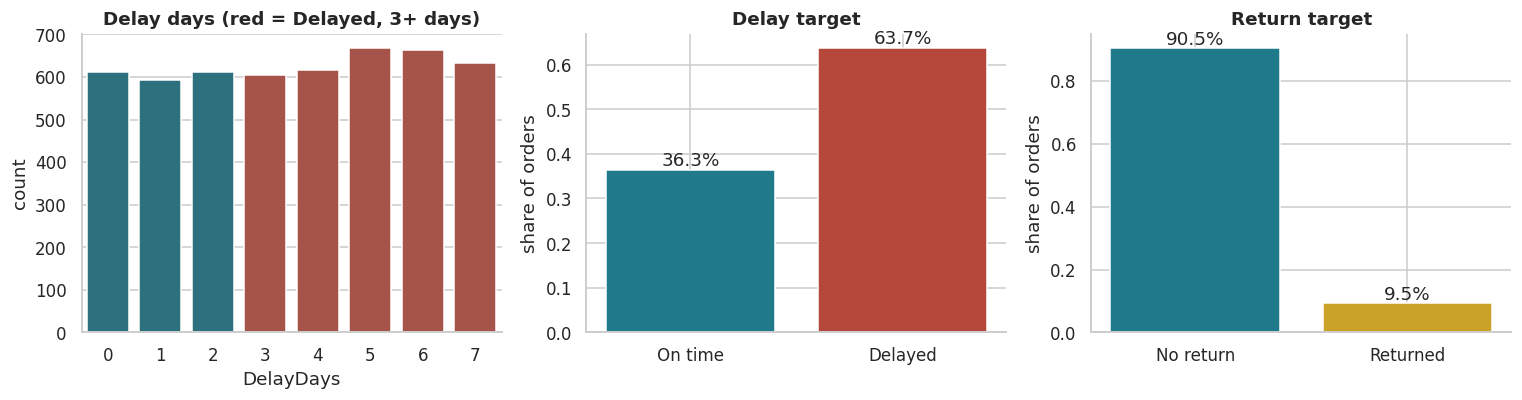

Delay target:  63.7% delayed  -> imbalance ratio 1.76:1 (mild)
Return target: 9.5% returned -> imbalance ratio 1:9.6 (strong, needs handling)


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
sns.countplot(x='DelayDays', hue='delayed', data=m, ax=ax[0], palette={0: TEAL, 1: RED}, dodge=False)
ax[0].set_title('Delay days (red = Delayed, 3+ days)'); ax[0].legend_.remove()
vc = m.delayed.value_counts(normalize=True).sort_index()
ax[1].bar(['On time','Delayed'], vc.values, color=[TEAL, RED]); ax[1].set_title('Delay target'); ax[1].set_ylabel('share of orders')
for i, v in enumerate(vc.values): ax[1].text(i, v + .01, f'{v:.1%}', ha='center')
vr = m.returned.value_counts(normalize=True).sort_index()
ax[2].bar(['No return','Returned'], vr.values, color=[TEAL, GOLD]); ax[2].set_title('Return target'); ax[2].set_ylabel('share of orders')
for i, v in enumerate(vr.values): ax[2].text(i, v + .01, f'{v:.1%}', ha='center')
savefig('01_target_distributions')

print(f"Delay target:  {m.delayed.mean():.1%} delayed  -> imbalance ratio {m.delayed.mean()/(1-m.delayed.mean()):.2f}:1 (mild)")
print(f"Return target: {m.returned.mean():.1%} returned -> imbalance ratio 1:{(1-m.returned.mean())/m.returned.mean():.1f} (strong, needs handling)")

**Class imbalance.** The delay target is mildly imbalanced (about 64/36) and the return target is strongly imbalanced
(about 9.5% positive). A model that always answers "no return" would be 90% accurate and useless, so **accuracy is not used
to judge the return model**. Imbalance is handled with class weights, and ROC-AUC, recall and F1 are reported alongside accuracy.

In [10]:
miss = pd.DataFrame({'missing': m.isna().sum(), 'pct': (m.isna().mean()*100).round(2)})
print('Missing values in the modelling table (before imputation):'); display(miss[miss.missing > 0])
print('\nThe only gaps are the first-order history features: a customer\'s first order has no history,'
      '\nso these are imputed inside the pipeline (median), not dropped.')

Missing values in the modelling table (before imputation):


,missing,pct
cust_prior_delay_rate,991,19.82
cust_prior_return_rate,991,19.82



The only gaps are the first-order history features: a customer's first order has no history,
so these are imputed inside the pipeline (median), not dropped.


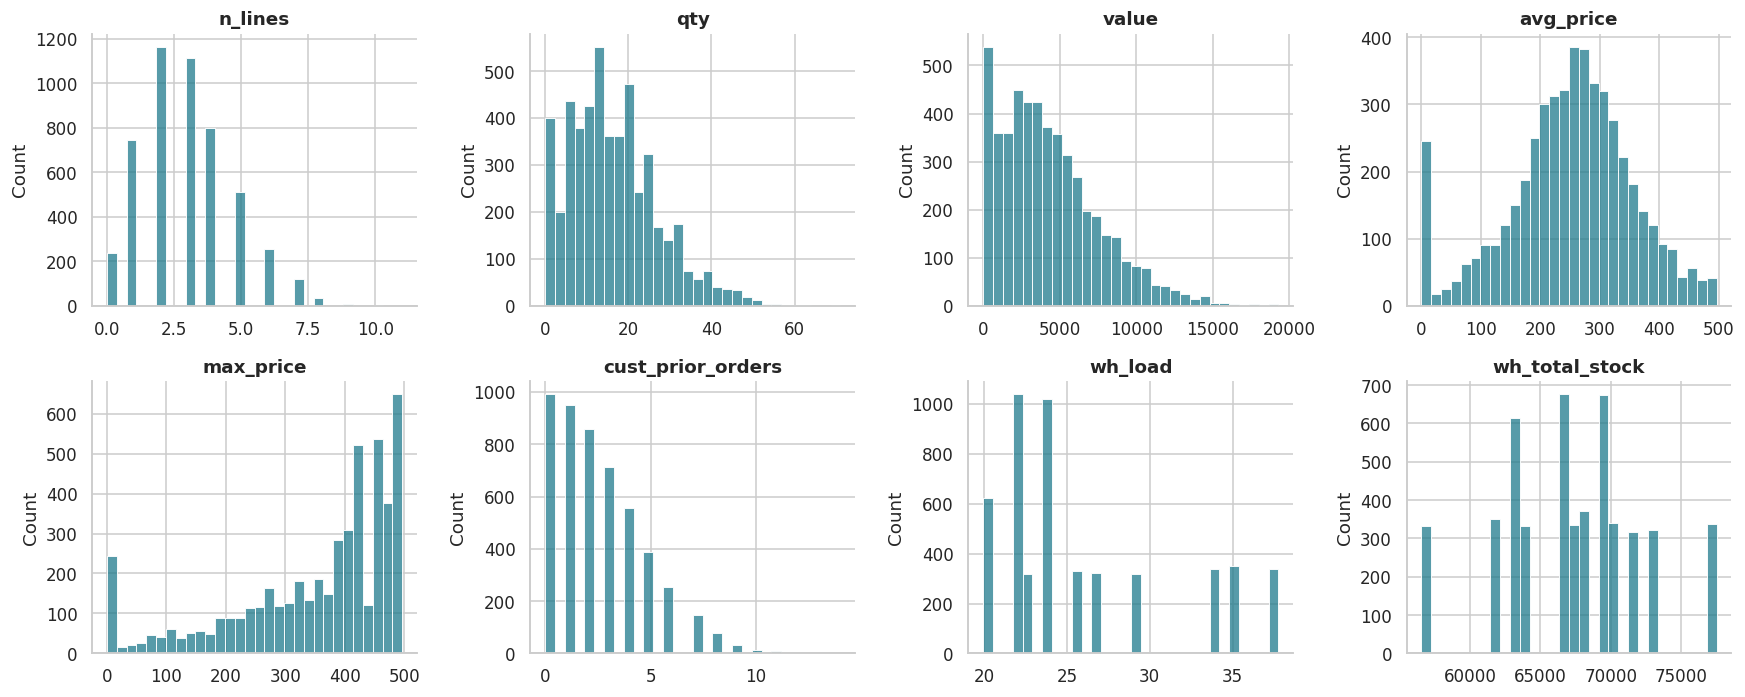

Outlier detection (1.5 x IQR rule, orders with items):


,feature,q1,q3,outliers_iqr,pct,max
0,n_lines,2.000000,4.0000,54,1.13,11.00
1,qty,10.000000,23.0000,114,2.39,71.00
2,value,2168.370000,6280.2525,106,2.23,19290.34
3,avg_price,203.480625,320.3800,19,0.40,496.61
4,max_price,298.450000,457.2000,59,1.24,496.61


In [11]:
NUM_EDA = ['n_lines','qty','value','avg_price','max_price','cust_prior_orders','wh_load','wh_total_stock']
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for a, c in zip(axes.ravel(), NUM_EDA):
    sns.histplot(m[c], bins=30, ax=a, color=TEAL); a.set_title(c); a.set_xlabel('')
savefig('02_feature_distributions')

rows = []
for c in ['n_lines','qty','value','avg_price','max_price']:
    x = m.loc[m.has_items == 1, c]; q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    out = ((x < q1 - 1.5*iqr) | (x > q3 + 1.5*iqr)).sum()
    rows.append(dict(feature=c, q1=q1, q3=q3, outliers_iqr=int(out), pct=round(100*out/len(x), 2), max=x.max()))
print('Outlier detection (1.5 x IQR rule, orders with items):'); pd.DataFrame(rows)

Basket features are right-skewed (a few large orders) but the IQR rule flags almost nothing, and the largest values are
genuine large orders (e.g. 10 units of a premium product), not errors. **Outliers are kept**; the scaler and tree models cope.

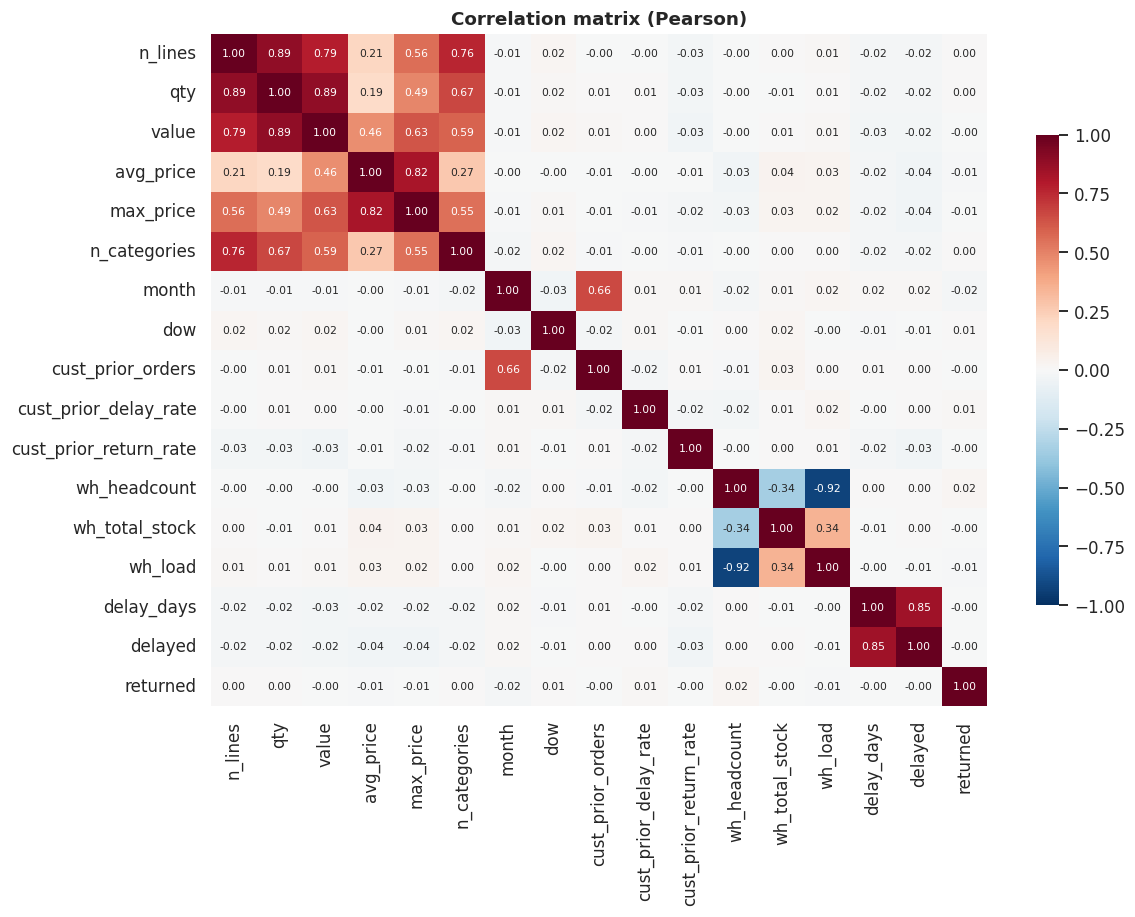

Strongest absolute correlation with each target:


,delayed,returned
max_price,0.037,0.008
avg_price,0.035,0.008
cust_prior_return_rate,0.033,0.004
value,0.025,0.005
n_categories,0.020,0.001
n_lines,0.019,0.001


In [12]:
corr_cols = ['n_lines','qty','value','avg_price','max_price','n_categories','month','dow','cust_prior_orders',
             'cust_prior_delay_rate','cust_prior_return_rate','wh_headcount','wh_total_stock','wh_load','delay_days','delayed','returned']
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(m[corr_cols].corr(), cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 7}, ax=ax, cbar_kws={'shrink': .7})
ax.set_title('Correlation matrix (Pearson)'); savefig('03_correlation_heatmap')

tc = m[corr_cols].corr()[['delayed','returned']].drop(['delayed','returned','delay_days']).abs().sort_values('delayed', ascending=False)
print('Strongest absolute correlation with each target:'); display(tc.head(6).round(3))

Apart from the obvious links (value with quantity and price), **no feature has a meaningful correlation with either target**
(the largest absolute correlation with either target is about 3.7%). The next cells test that formally instead of eyeballing it.

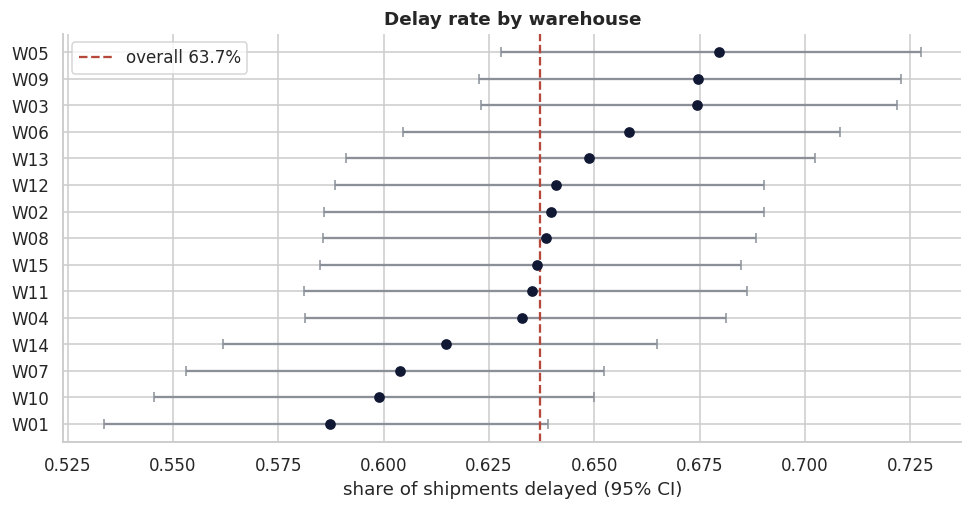

In [13]:
def wilson(k, n, z=1.96):
    p = k/n; d = 1 + z*z/n; c = p + z*z/(2*n); w = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))
    return (c - w)/d, (c + w)/d

g = m.groupby('WarehouseID').delayed.agg(['sum','count']).reset_index()
g['rate'] = g['sum']/g['count']; g[['lo','hi']] = g.apply(lambda r: pd.Series(wilson(r['sum'], r['count'])), axis=1)
g = g.sort_values('rate')
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.errorbar(g.rate, range(len(g)), xerr=[g.rate-g.lo, g.hi-g.rate], fmt='o', color=NAVY, ecolor=GREY, capsize=3)
ax.axvline(m.delayed.mean(), color=RED, ls='--', label=f'overall {m.delayed.mean():.1%}')
ax.set_yticks(range(len(g))); ax.set_yticklabels(g.WarehouseID); ax.set_xlabel('share of shipments delayed (95% CI)')
ax.set_title('Delay rate by warehouse'); ax.legend(); savefig('04_delay_by_warehouse')

In [14]:
res = []
for target in ['delayed','returned']:
    for cat in ['WarehouseID','wh_location','City','month','dow']:
        chi2, pval, dof, _ = stats.chi2_contingency(pd.crosstab(m[cat], m[target]))
        res.append(dict(target=target, feature=cat, test='chi-square', statistic=round(chi2, 2), p_value=round(pval, 3)))
    for num in ['n_lines','qty','value','avg_price','wh_load','cust_prior_orders']:
        a, b = m.loc[m[target]==1, num], m.loc[m[target]==0, num]
        u, pval = stats.mannwhitneyu(a, b)
        res.append(dict(target=target, feature=num, test='Mann-Whitney U', statistic=round(u, 0), p_value=round(pval, 3)))
tests = pd.DataFrame(res)
tests['significant_5pct'] = tests.p_value < 0.05
print(f"{tests.significant_5pct.sum()} of {len(tests)} tests significant at 5% (about {0.05*len(tests):.1f} expected by chance alone)")
tests.to_csv(PROC/'statistical_tests.csv', index=False); tests

1 of 22 tests significant at 5% (about 1.1 expected by chance alone)


,target,feature,test,statistic,p_value,significant_5pct
0,delayed,WarehouseID,chi-square,15.76,0.328,False
1,delayed,wh_location,chi-square,1.03,0.598,False
2,delayed,City,chi-square,6.27,0.099,False
3,delayed,month,chi-square,8.60,0.378,False
4,delayed,dow,chi-square,3.16,0.789,False
5,delayed,n_lines,Mann-Whitney U,2821344.00,0.157,False
6,delayed,qty,Mann-Whitney U,2837688.00,0.289,False
7,delayed,value,Mann-Whitney U,2808960.00,0.100,False
8,delayed,avg_price,Mann-Whitney U,2785548.00,0.034,True
9,delayed,wh_load,Mann-Whitney U,2896540.00,0.889,False


Out of 22 hypothesis tests, the number below the 5% threshold is about what random chance alone would produce.
Warehouse, city, month, weekday and basket size show **no statistically detectable relationship with delay or returns**.
That is the statistical version of what the correlation matrix suggested, and it sets the realistic ceiling for every model.

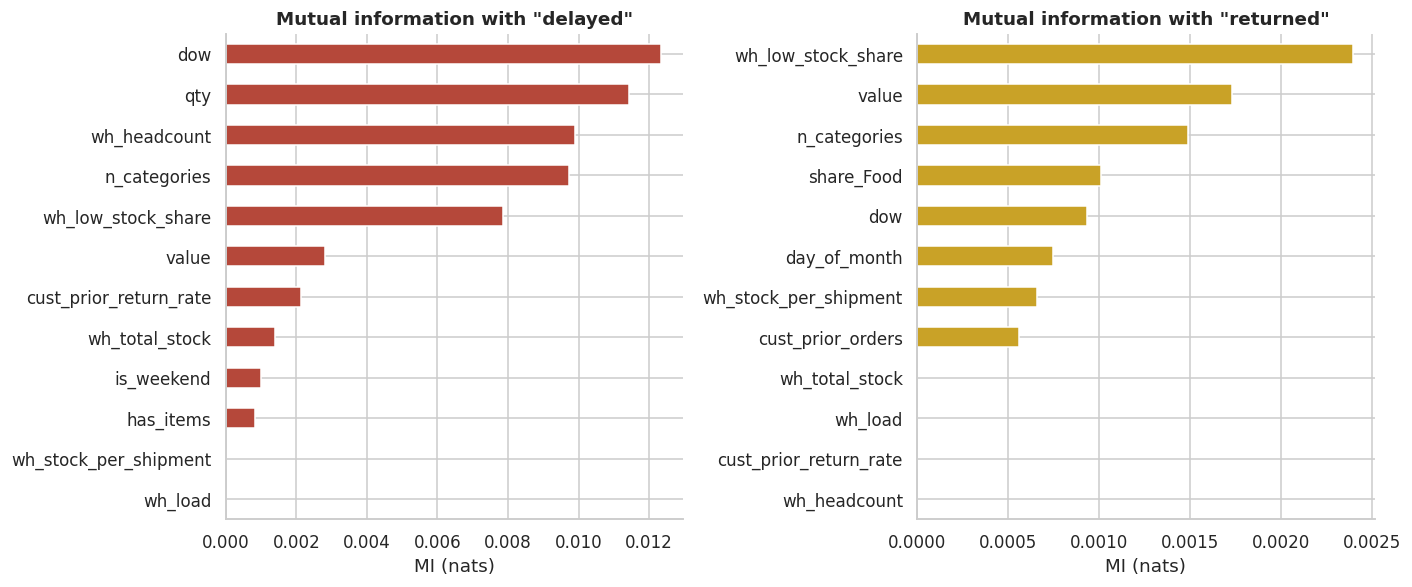

Maximum mutual information: {'delayed': 0.0123, 'returned': 0.0024}  -> essentially zero (noise level)


In [15]:
Xe = m[[c for fg in FEATURE_GROUPS.values() for c in fg if c not in ('WarehouseID','wh_location','City')]].fillna(0)
mi = pd.DataFrame({'delayed': mutual_info_classif(Xe, m.delayed, random_state=SEED),
                   'returned': mutual_info_classif(Xe, m.returned, random_state=SEED)}, index=Xe.columns)
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5), sharex=False)
for a, t, col in zip(ax, ['delayed','returned'], [RED, GOLD]):
    mi[t].sort_values().tail(12).plot.barh(ax=a, color=col); a.set_title(f'Mutual information with "{t}"'); a.set_xlabel('MI (nats)')
savefig('05_mutual_information')
print('Maximum mutual information:', mi.max().round(4).to_dict(), ' -> essentially zero (noise level)')

Feature-importance exploration with mutual information agrees: every score is at noise level (tiny and unordered).

### Demand and customer-level views
The remaining two problems are not order-level, so they need their own tables: a **product-by-month demand panel**
(forecasting) and a **customer table** (value prediction). Both are built from non-cancelled orders, because a cancelled order
is not demand that had to be served.

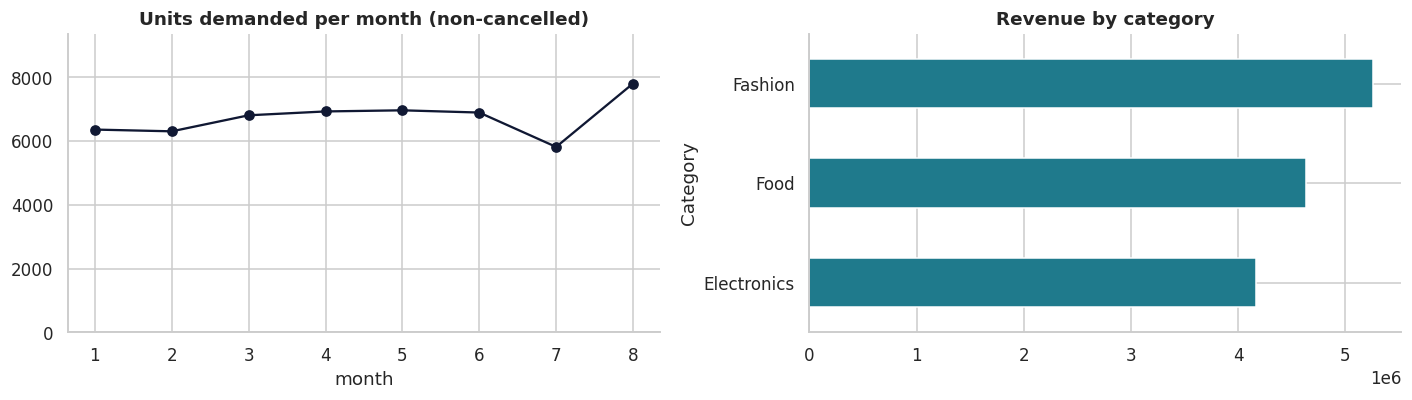

Panel: (250, 8) (products x months 1-8). Mean units per product-month: 26.9 | std: 13.8
Month-to-month correlation of a product's own demand (lag-1): 0.018


In [16]:
act = items.merge(orders[['OrderID','CustomerID','OrderDate','Status']], on='OrderID')
act['month'] = act.OrderDate.dt.month
act = act[(act.Status != 'Cancelled') & (act.month <= 8)]        # drop cancelled orders and the partial September

monthly = act.groupby('month').agg(units=('Quantity','sum'), revenue=('line_value','sum'))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
monthly.units.plot(marker='o', ax=ax[0], color=NAVY); ax[0].set_title('Units demanded per month (non-cancelled)'); ax[0].set_ylim(0, monthly.units.max()*1.2)
cat_rev = act.groupby('Category').line_value.sum().sort_values(); cat_rev.plot.barh(ax=ax[1], color=TEAL); ax[1].set_title('Revenue by category')
savefig('06_demand_overview')

panel_raw = act.pivot_table(index='ProductID', columns='month', values='Quantity', aggfunc='sum', fill_value=0)
print('Panel:', panel_raw.shape, '(products x months 1-8). Mean units per product-month:', round(panel_raw.values.mean(), 1),
      '| std:', round(panel_raw.values.std(), 1))
print('Month-to-month correlation of a product\'s own demand (lag-1):', round(np.corrcoef(panel_raw.iloc[:, :-1].values.ravel(), panel_raw.iloc[:, 1:].values.ravel())[0, 1], 3))

Total monthly demand is flat (no trend, no seasonal pattern) and a product's demand in one month is **uncorrelated with its
own demand the month before** (lag-1 correlation about zero). Forecasting models normally live off exactly that
autocorrelation, so this predicts a hard task before a single model is trained.

## 5. Modelling framework (Parts 3 and 4)

**Design rules applied to every model**
* All preprocessing (imputation, scaling, one-hot encoding) lives **inside a scikit-learn `Pipeline`**, so it is fitted on training data only: no leakage through scaling or imputation.
* **Train / validation / test = 70 / 15 / 15** for the order-level classification problems (stratified, `random_state=42`). The two forecasting problems use a **time-based** split because shuffling would leak the future into the past.
* **Three or more algorithms per problem**, each against a **naive baseline** (the model has to beat predicting the average).
* 5-fold cross-validation on the training set for every candidate, then hyper-parameter tuning (`GridSearchCV` and `RandomizedSearchCV`), then feature selection inside the pipeline.
* The **test set is touched once**, for the selected model only.
* **Selection rule: the one-standard-error rule.** Among candidates whose CV score is within one standard error of the best, pick the simplest. When models are statistically tied this avoids rewarding noise with a complicated model.

In [17]:
COMPLEXITY = {'Logistic Regression': 1, 'Linear Regression': 1, 'Ridge Regression': 1, 'Decision Tree': 2,
              'Random Forest': 4, 'Gradient Boosting': 4, 'XGBoost': 5}

def make_preprocessor(num_cols, cat_cols):
    num = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())])
    cat = Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    return ColumnTransformer([('num', num, num_cols), ('cat', cat, cat_cols)])

def clf_metrics(y, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0), f1=f1_score(y, pred, zero_division=0), roc_auc=roc_auc_score(y, proba))

def reg_metrics(y, pred):
    mse = mean_squared_error(y, pred)
    return dict(MAE=mean_absolute_error(y, pred), MSE=mse, RMSE=np.sqrt(mse), R2=r2_score(y, pred))

def clf_zoo(pos_weight):
    return {
     'Logistic Regression': LogisticRegression(max_iter=3000, class_weight='balanced', random_state=SEED),
     'Decision Tree':       DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, class_weight='balanced', random_state=SEED),
     'Random Forest':       RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight='balanced', n_jobs=-1, random_state=SEED),
     'Gradient Boosting':   GradientBoostingClassifier(random_state=SEED),
     'XGBoost':             XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                          scale_pos_weight=pos_weight, eval_metric='logloss', random_state=SEED, n_jobs=4, verbosity=0)}

def reg_zoo():
    return {
     'Linear Regression': LinearRegression(),
     'Ridge Regression':  Ridge(alpha=10.0),
     'Random Forest':     RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
     'Gradient Boosting': GradientBoostingRegressor(random_state=SEED),
     'XGBoost':           XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                       random_state=SEED, n_jobs=4, verbosity=0)}

def tuning_plans(kind):
    """Hyper-parameter search spaces. Keys are model names; values are (searcher, estimator-step param grid)."""
    if kind == 'clf':
        return {
         'Logistic Regression': ('grid', {'select__k': [5, 10, 20, 'all'], 'clf__C': [0.01, 0.1, 1, 10]}),
         'Random Forest':       ('random', {'clf__n_estimators': [200, 400], 'clf__max_depth': [3, 5, 8, None],
                                            'clf__min_samples_leaf': [5, 20, 50], 'clf__max_features': ['sqrt', 0.5]}),
         'Gradient Boosting':   ('random', {'clf__n_estimators': [100, 200, 300], 'clf__learning_rate': [0.01, 0.05, 0.1],
                                            'clf__max_depth': [2, 3, 4], 'clf__subsample': [0.7, 1.0]}),
         'XGBoost':             ('random', {'clf__n_estimators': [100, 200, 300], 'clf__learning_rate': [0.01, 0.05, 0.1],
                                            'clf__max_depth': [2, 3, 4], 'clf__min_child_weight': [1, 5, 10]})}
    return {
     'Ridge Regression':  ('grid', {'select__k': [5, 10, 'all'], 'reg__alpha': [1, 10, 100, 1000]}),
     'Random Forest':     ('random', {'reg__n_estimators': [200, 400], 'reg__max_depth': [3, 5, 8, None],
                                      'reg__min_samples_leaf': [5, 10, 30], 'reg__max_features': ['sqrt', 0.5]}),
     'Gradient Boosting': ('random', {'reg__n_estimators': [100, 200, 300], 'reg__learning_rate': [0.01, 0.05, 0.1],
                                      'reg__max_depth': [2, 3, 4], 'reg__subsample': [0.7, 1.0]}),
     'XGBoost':           ('random', {'reg__n_estimators': [100, 200, 300], 'reg__learning_rate': [0.01, 0.05, 0.1],
                                      'reg__max_depth': [2, 3, 4], 'reg__min_child_weight': [1, 5, 10]})}

In [18]:
def build_pipe(est, num_cols, cat_cols, kind, k='all'):
    sel = SelectKBest(mutual_info_classif if kind == 'clf' else mutual_info_regression, k=k)
    step = 'clf' if kind == 'clf' else 'reg'
    return Pipeline([('prep', make_preprocessor(num_cols, cat_cols)), ('select', sel), (step, est)])

def feature_names(pipe):
    names = pipe[:-1].get_feature_names_out()
    return [n.split('__', 1)[-1] for n in names]

def one_se_select(table, higher_is_better=True, score='cv_mean', err='cv_std', n_folds=5):
    """One-standard-error rule: simplest model whose CV score is within 1 SE of the best."""
    t = table.copy(); sign = 1 if higher_is_better else -1
    best = t.loc[(sign*t[score]).idxmax()]; se = best[err]/np.sqrt(n_folds)
    ok = t[(sign*t[score]) >= sign*best[score] - se]
    ok = ok.assign(cx=ok.base_model.map(COMPLEXITY)).sort_values(['cx', score], ascending=[True, not higher_is_better])
    return ok.index[0], float(se)

def bootstrap_ci(y, proba, n=1000, seed=SEED):
    rng = np.random.default_rng(seed); y = np.asarray(y); proba = np.asarray(proba); out = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2: out.append(roc_auc_score(y[i], proba[i]))
    return np.percentile(out, [2.5, 97.5])

### 5.1 Reusable classification experiment
One function runs the whole protocol (baseline, candidates, tuning, selection, test) so that the delay and return models are
treated *identically* and the comparison is fair.

In [19]:
def run_classification(name, X, y, num_cols, cat_cols, tune_models=('Logistic Regression','Random Forest','Gradient Boosting','XGBoost')):
    t0 = time.time()
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
    print(f'[{name}] train {len(X_tr)} | validation {len(X_va)} | test {len(X_te)} | positive rate {y.mean():.3f}')
    pos_w = (1 - y_tr.mean()) / y_tr.mean()
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    rows, fitted = [], {}

    base = Pipeline([('prep', make_preprocessor(num_cols, cat_cols)), ('clf', DummyClassifier(strategy='prior'))]).fit(X_tr, y_tr)
    rows.append(dict(model='Baseline (predict prevalence)', base_model='Baseline', variant='Baseline', cv_mean=0.5, cv_std=0.0,
                     **{f'val_{k}': v for k, v in clf_metrics(y_va, base.predict_proba(X_va)[:, 1]).items()}))

    # (a) default candidates
    for mname, est in clf_zoo(pos_w).items():
        pipe = build_pipe(est, num_cols, cat_cols, 'clf').fit(X_tr, y_tr)
        sc = cross_validate(pipe, X_tr, y_tr, cv=cv, scoring=['roc_auc','f1'], n_jobs=1)
        key = f'{mname} (default)'; fitted[key] = pipe
        rows.append(dict(model=key, base_model=mname, variant='Default', cv_mean=sc['test_roc_auc'].mean(), cv_std=sc['test_roc_auc'].std(),
                         cv_f1=sc['test_f1'].mean(), **{f'val_{k}': v for k, v in clf_metrics(y_va, pipe.predict_proba(X_va)[:, 1]).items()}))
    # (b) tuned candidates (feature selection is part of the search space for the linear model)
    plans = tuning_plans('clf')
    for mname in tune_models:
        kind, grid = plans[mname]
        pipe0 = build_pipe(clf_zoo(pos_w)[mname], num_cols, cat_cols, 'clf')
        if mname != 'Logistic Regression': grid = {k: v for k, v in grid.items() if not k.startswith('select__')}
        search = (GridSearchCV(pipe0, grid, scoring='roc_auc', cv=3, n_jobs=1) if kind == 'grid'
                  else RandomizedSearchCV(pipe0, grid, n_iter=10, scoring='roc_auc', cv=3, n_jobs=1, random_state=SEED))
        search.fit(X_tr, y_tr); best = search.best_estimator_
        sc = cross_validate(best, X_tr, y_tr, cv=cv, scoring=['roc_auc','f1'], n_jobs=1)
        key = f'{mname} (tuned)'; fitted[key] = best
        rows.append(dict(model=key, base_model=mname, variant='Tuned', cv_mean=sc['test_roc_auc'].mean(), cv_std=sc['test_roc_auc'].std(),
                         cv_f1=sc['test_f1'].mean(), best_params={k.split('__')[-1]: v for k, v in search.best_params_.items()},
                         **{f'val_{k}': v for k, v in clf_metrics(y_va, best.predict_proba(X_va)[:, 1]).items()}))

    tab = pd.DataFrame(rows).set_index('model')
    cand = tab[tab.base_model != 'Baseline']
    sel, se = one_se_select(cand)
    best_cv = cand.cv_mean.max()
    pipe = fitted[sel]; proba_te = pipe.predict_proba(X_te)[:, 1]
    test = clf_metrics(y_te, proba_te); lo, hi = bootstrap_ci(y_te, proba_te)

    # label-shuffle check: does the selected model beat chance? (CV AUC when the labels are randomly permuted)
    rng = np.random.default_rng(SEED); null = []
    for _ in range(5):
        yp = pd.Series(rng.permutation(y_tr.values), index=y_tr.index)
        null.append(cross_validate(pipe, X_tr, yp, cv=cv, scoring='roc_auc')['test_score'].mean())

    print(f'[{name}] best CV AUC {best_cv:.3f} | one-SE band {se:.3f} -> selected: {sel}')
    print(f'[{name}] TEST  AUC {test["roc_auc"]:.3f} (95% CI {lo:.3f} to {hi:.3f}) | label-shuffled CV AUC {np.mean(null):.3f}  [{time.time()-t0:.0f}s]')
    return dict(name=name, table=tab, selected=sel, pipe=pipe, fitted=fitted, X_tr=X_tr, X_va=X_va, X_te=X_te, y_tr=y_tr, y_va=y_va, y_te=y_te,
                proba_te=proba_te, test=test, auc_ci=(lo, hi), null_auc=float(np.mean(null)), se=se)

### 5.2 Model 1: Delivery Delay Prediction (classification)
**Target:** `delayed` (3 or more days late). **Question:** can SwiftLog flag at-risk shipments *before* dispatch?
**Features:** only what is known before shipping: basket, calendar, customer history, warehouse profile and location. Excluded:
`DelayDays`/`Status` (define the target), order status (settled after delivery) and return history (happens after delivery).

In [20]:
DELAY_NUM = ['n_lines','qty','value','avg_price','max_price','n_categories','share_Electronics','share_Fashion','share_Food','has_items',
             'month','dow','is_weekend','day_of_month','cust_prior_orders','cust_prior_delay_rate',
             'wh_headcount','wh_total_stock','wh_low_stock_share','wh_load','wh_stock_per_shipment']
DELAY_CAT = ['WarehouseID','wh_location','City']
delay = run_classification('Delivery Delay', m[DELAY_NUM + DELAY_CAT], m.delayed, DELAY_NUM, DELAY_CAT)

[Delivery Delay] train 3500 | validation 750 | test 750 | positive rate 0.637


[Delivery Delay] best CV AUC 0.518 | one-SE band 0.011 -> selected: Logistic Regression (tuned)
[Delivery Delay] TEST  AUC 0.520 (95% CI 0.476 to 0.563) | label-shuffled CV AUC 0.500  [178s]


In [21]:
show = ['cv_mean','cv_std','val_accuracy','val_precision','val_recall','val_f1','val_roc_auc']
delay['table'][show].round(3).style.background_gradient(subset=['cv_mean'], cmap='Blues').format(precision=3)

,cv_mean,cv_std,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc
model,,,,,,,
Baseline (predict prevalence),0.500,0.000,0.637,0.637,1.000,0.779,0.500
Logistic Regression (default),0.511,0.009,0.488,0.628,0.483,0.546,0.499
Decision Tree (default),0.506,0.009,0.551,0.639,0.678,0.658,0.494
Random Forest (default),0.508,0.015,0.568,0.641,0.732,0.684,0.493
Gradient Boosting (default),0.503,0.015,0.629,0.639,0.962,0.768,0.514
XGBoost (default),0.517,0.016,0.509,0.634,0.544,0.586,0.514
Logistic Regression (tuned),0.518,0.025,0.567,0.645,0.713,0.677,0.501
Random Forest (tuned),0.513,0.021,0.600,0.643,0.837,0.727,0.489
Gradient Boosting (tuned),0.509,0.015,0.601,0.637,0.872,0.736,0.519


### 5.3 Model 2: Product Return Prediction (classification)
**Target:** `returned` (the order has a return record). **Features:** the delay features plus `delay_days` (the delivery
outcome is known by the time a customer decides to return) and `cust_prior_return_rate`. Because only about 9.5% of orders are
returned, class weights (`balanced` / `scale_pos_weight`) are used and the model is judged on ROC-AUC, recall and F1, not accuracy.

In [22]:
RET_NUM = DELAY_NUM + ['delay_days','cust_prior_return_rate']
ret = run_classification('Product Return', m[RET_NUM + DELAY_CAT], m.returned, RET_NUM, DELAY_CAT)
ret['table'][show].round(3).style.background_gradient(subset=['cv_mean'], cmap='Oranges').format(precision=3)

[Product Return] train 3500 | validation 750 | test 750 | positive rate 0.095


[Product Return] best CV AUC 0.499 | one-SE band 0.019 -> selected: Logistic Regression (tuned)
[Product Return] TEST  AUC 0.491 (95% CI 0.420 to 0.565) | label-shuffled CV AUC 0.494  [182s]


,cv_mean,cv_std,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc
model,,,,,,,
Baseline (predict prevalence),0.500,0.000,0.905,0.000,0.000,0.000,0.500
Logistic Regression (default),0.468,0.017,0.571,0.091,0.394,0.148,0.481
Decision Tree (default),0.494,0.019,0.536,0.103,0.507,0.171,0.545
Random Forest (default),0.486,0.047,0.904,0.333,0.014,0.027,0.557
Gradient Boosting (default),0.481,0.031,0.905,0.500,0.014,0.027,0.542
XGBoost (default),0.483,0.033,0.724,0.095,0.225,0.134,0.550
Logistic Regression (tuned),0.499,0.041,0.516,0.118,0.634,0.199,0.543
Random Forest (tuned),0.469,0.038,0.905,0.000,0.000,0.000,0.571
Gradient Boosting (tuned),0.472,0.040,0.901,0.000,0.000,0.000,0.578


**Class-imbalance handling, made visible.** The cell below compares the same Random Forest with and without class weights
on the validation set, so the effect of the imbalance handling is documented, not assumed.

In [23]:
def rf_pipe(weighted):
    est = RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight='balanced' if weighted else None, n_jobs=-1, random_state=SEED)
    return build_pipe(est, RET_NUM, DELAY_CAT, 'clf').fit(ret['X_tr'], ret['y_tr'])
cmp_rows = []
for weighted in (False, True):
    pr = rf_pipe(weighted).predict_proba(ret['X_va'])[:, 1]
    cmp_rows.append(dict(setting='class_weight=balanced' if weighted else 'no class weights', **{k: round(v, 3) for k, v in clf_metrics(ret['y_va'], pr).items()}))
pd.DataFrame(cmp_rows).set_index('setting')

,accuracy,precision,recall,f1,roc_auc
setting,,,,,
no class weights,0.905,0.000,0.000,0.000,0.508
class_weight=balanced,0.904,0.333,0.014,0.027,0.557


Without class weights the model almost never predicts a return, so recall collapses; with weights it flags many more, at the
cost of precision. ROC-AUC is unchanged because it does not depend on the threshold: **weights change the trade-off, they do not
create signal**.

### 5.4 Model 3: Product Demand Forecasting (regression)
**Target:** units of a product demanded **next month**. **Panel:** 250 products x months 1-8 (non-cancelled orders, partial September
excluded). **Features:** last month's demand, two-month lag, the product's own historical average, price, category, current stock
across warehouses and number of stocking sites. **Split by time:** training targets are months 3-6, validation is month 7, test is
month 8, so the model is always forecasting the future.

In [24]:
inv_p = inv.groupby('ProductID').agg(stock_total=('Stock','sum'), n_stock_sites=('WarehouseID','nunique')).reset_index()
rows = []
for t in range(3, 9):
    for pid in panel_raw.index:
        h = panel_raw.loc[pid, :t-1]
        rows.append(dict(ProductID=pid, month=t, y=panel_raw.loc[pid, t], lag1=panel_raw.loc[pid, t-1], lag2=panel_raw.loc[pid, t-2],
                         hist_mean=h.mean(), hist_std=h.std(), trend=np.polyfit(range(len(h)), h.values, 1)[0]))
dem = (pd.DataFrame(rows).merge(clean['Products'], on='ProductID').merge(inv_p, on='ProductID', how='left'))

DEM_NUM = ['lag1','lag2','hist_mean','hist_std','trend','UnitPrice','stock_total','n_stock_sites','month']
DEM_CAT = ['Category']
dtr, dva, dte = dem[dem.month <= 6], dem[dem.month == 7], dem[dem.month == 8]
print('train', dtr.shape, '| validation', dva.shape, '| test', dte.shape)
print('Target mean (train):', round(dtr.y.mean(), 2), '| std:', round(dtr.y.std(), 2))

train (1000, 12) | validation (250, 12) | test (250, 12)
Target mean (train): 27.6 | std: 13.83


In [25]:
def run_regression(name, tr, va, te, num_cols, cat_cols, target, cv, baselines, tune=('Ridge Regression','Random Forest','Gradient Boosting','XGBoost')):
    t0 = time.time(); Xtr, ytr, Xva, yva, Xte, yte = tr[num_cols+cat_cols], tr[target], va[num_cols+cat_cols], va[target], te[num_cols+cat_cols], te[target]
    rows, fitted = [], {}
    for bname, fn in baselines.items():
        rows.append(dict(model=bname, base_model='Baseline', variant='Baseline', cv_mean=np.nan, cv_std=np.nan,
                         **{f'val_{k}': v for k, v in reg_metrics(yva, fn(va, tr)).items()}))
    def cvrmse(p):
        s = cross_validate(p, Xtr, ytr, cv=cv, scoring='neg_root_mean_squared_error'); return -s['test_score'].mean(), s['test_score'].std()
    for mname, est in reg_zoo().items():
        pipe = build_pipe(est, num_cols, cat_cols, 'reg').fit(Xtr, ytr); key = f'{mname} (default)'; fitted[key] = pipe; mu, sd = cvrmse(pipe)
        rows.append(dict(model=key, base_model=mname, variant='Default', cv_mean=mu, cv_std=sd, **{f'val_{k}': v for k, v in reg_metrics(yva, pipe.predict(Xva)).items()}))
    plans = tuning_plans('reg')
    for mname in tune:
        kind, grid = plans[mname]
        pipe0 = build_pipe(reg_zoo()[mname], num_cols, cat_cols, 'reg')
        if mname != 'Ridge Regression': grid = {k: v for k, v in grid.items() if not k.startswith('select__')}
        search = (GridSearchCV(pipe0, grid, scoring='neg_root_mean_squared_error', cv=cv, n_jobs=1) if kind == 'grid'
                  else RandomizedSearchCV(pipe0, grid, n_iter=10, scoring='neg_root_mean_squared_error', cv=cv, n_jobs=1, random_state=SEED))
        search.fit(Xtr, ytr); best = search.best_estimator_; mu, sd = cvrmse(best); key = f'{mname} (tuned)'; fitted[key] = best
        rows.append(dict(model=key, base_model=mname, variant='Tuned', cv_mean=mu, cv_std=sd, best_params={k.split('__')[-1]: v for k, v in search.best_params_.items()},
                         **{f'val_{k}': v for k, v in reg_metrics(yva, best.predict(Xva)).items()}))
    tab = pd.DataFrame(rows).set_index('model'); cand = tab[tab.base_model != 'Baseline']
    sel, se = one_se_select(cand, higher_is_better=False, n_folds=cv.get_n_splits())
    pipe = fitted[sel]; pred_te = pipe.predict(Xte)
    base_te = {b: reg_metrics(yte, fn(te, tr)) for b, fn in baselines.items()}
    print(f'[{name}] selected: {sel} (CV RMSE {cand.loc[sel, "cv_mean"]:.2f}, one-SE band {se:.2f}) [{time.time()-t0:.0f}s]')
    print(f'[{name}] TEST', {k: round(v, 3) for k, v in reg_metrics(yte, pred_te).items()})
    print(f'[{name}] TEST baselines', {b: {k: round(v, 3) for k, v in d.items() if k in ("RMSE","R2")} for b, d in base_te.items()})
    return dict(name=name, table=tab, selected=sel, pipe=pipe, fitted=fitted, X_tr=Xtr, y_tr=ytr, X_va=Xva, y_va=yva, X_te=Xte, y_te=yte, pred_te=pred_te, test=reg_metrics(yte, pred_te), base_test=base_te, se=se)

dem_baselines = {'Baseline: training mean':    lambda d, tr: np.full(len(d), tr.y.mean()),
                 'Baseline: last month (naive)': lambda d, tr: d.lag1.values,
                 'Baseline: product history mean': lambda d, tr: d.hist_mean.values}
demand = run_regression('Demand Forecasting', dtr, dva, dte, DEM_NUM, DEM_CAT, 'y', TimeSeriesSplit(4), dem_baselines)

[Demand Forecasting] selected: Ridge Regression (tuned) (CV RMSE 13.85, one-SE band 0.28) [42s]
[Demand Forecasting] TEST {'MAE': 11.303, 'MSE': 217.6, 'RMSE': np.float64(14.751), 'R2': -0.058}
[Demand Forecasting] TEST baselines {'Baseline: training mean': {'RMSE': np.float64(14.793), 'R2': -0.064}, 'Baseline: last month (naive)': {'RMSE': np.float64(20.498), 'R2': -1.042}, 'Baseline: product history mean': {'RMSE': np.float64(16.053), 'R2': -0.253}}


In [26]:
rshow = ['cv_mean','cv_std','val_MAE','val_RMSE','val_R2']
demand['table'][rshow].round(3).rename(columns={'cv_mean':'cv_RMSE','cv_std':'cv_RMSE_std'}).style.format(precision=3)

,cv_RMSE,cv_RMSE_std,val_MAE,val_RMSE,val_R2
model,,,,,
Baseline: training mean,nan,nan,10.688,13.091,-0.123
Baseline: last month (naive),nan,nan,15.240,18.761,-1.306
Baseline: product history mean,nan,nan,11.195,13.951,-0.275
Linear Regression (default),14.036,0.389,10.721,13.167,-0.136
Ridge Regression (default),13.994,0.431,10.723,13.168,-0.136
Random Forest (default),14.191,0.497,10.872,13.460,-0.187
Gradient Boosting (default),14.833,0.531,10.890,13.521,-0.198
XGBoost (default),14.841,0.503,10.903,13.464,-0.188
Ridge Regression (tuned),13.848,0.566,10.711,13.126,-0.129


### 5.5 Model 4: Customer Value Prediction (regression)
**Target:** a customer's **future spend** (non-cancelled order value in months 6 to 9). **Features** come strictly from the earlier
window (months 1 to 5): spend, units, order count, average order value, return count, plus city. Predicting *future* spend from *past*
behaviour is the honest, useful version; predicting total spend from the same orders that make it up would be circular.
Customers are split at random (70/15/15) because each customer is one independent row.

In [27]:
nc = items.merge(orders[['OrderID','CustomerID','OrderDate','Status']], on='OrderID'); nc = nc[nc.Status != 'Cancelled']; nc['month'] = nc.OrderDate.dt.month
early = nc[nc.month <= 5].groupby('CustomerID').agg(spend_early=('line_value','sum'), units_early=('Quantity','sum'), orders_early=('OrderID','nunique'))
late  = nc[nc.month >= 6].groupby('CustomerID').line_value.sum().rename('future_spend')
ret_c = orders[orders.OrderDate.dt.month <= 5].merge(clean['Returns'], on='OrderID').groupby('CustomerID').size().rename('returns_early')
cust = (clean['Customers'].merge(early, on='CustomerID', how='left').merge(ret_c, on='CustomerID', how='left').merge(late, on='CustomerID', how='left')
        .fillna({'spend_early': 0, 'units_early': 0, 'orders_early': 0, 'returns_early': 0, 'future_spend': 0}))
cust['avg_order_value_early'] = np.where(cust.orders_early > 0, cust.spend_early / cust.orders_early.clip(lower=1), np.nan)
cust['active_early'] = (cust.orders_early > 0).astype(int)

CUST_NUM = ['spend_early','units_early','orders_early','returns_early','avg_order_value_early','active_early']; CUST_CAT = ['City']
ctr, ctmp = train_test_split(cust, test_size=0.30, random_state=SEED); cva, cte = train_test_split(ctmp, test_size=0.50, random_state=SEED)
print('customers: train', len(ctr), '| validation', len(cva), '| test', len(cte), '| future spend mean', round(cust.future_spend.mean(), 0), '| zero-spend share', f'{(cust.future_spend == 0).mean():.1%}')
print('Correlation, early spend vs future spend:', round(cust.spend_early.corr(cust.future_spend), 3))

cust_baselines = {'Baseline: training mean': lambda d, tr: np.full(len(d), tr.future_spend.mean())}
custv = run_regression('Customer Value', ctr, cva, cte, CUST_NUM, CUST_CAT, 'future_spend', KFold(5, shuffle=True, random_state=SEED), cust_baselines)
custv['table'][rshow].round(3).rename(columns={'cv_mean':'cv_RMSE','cv_std':'cv_RMSE_std'}).style.format(precision=3)

customers: train 700 | validation 150 | test 150 | future spend mean 5725.0 | zero-spend share 26.7%
Correlation, early spend vs future spend: -0.002


[Customer Value] selected: Ridge Regression (tuned) (CV RMSE 6134.60, one-SE band 212.04) [47s]
[Customer Value] TEST {'MAE': 5118.127, 'MSE': 39942523.97, 'RMSE': np.float64(6320.01), 'R2': -0.003}
[Customer Value] TEST baselines {'Baseline: training mean': {'RMSE': np.float64(6313.472), 'R2': -0.0}}


,cv_RMSE,cv_RMSE_std,val_MAE,val_RMSE,val_R2
model,,,,,
Baseline: training mean,nan,nan,4896.922,6229.169,-0.002
Linear Regression (default),6158.614,468.955,4928.681,6306.674,-0.027
Ridge Regression (default),6151.595,466.836,4925.746,6301.062,-0.025
Random Forest (default),6353.289,450.066,4896.921,6259.702,-0.012
Gradient Boosting (default),6503.339,442.381,5100.406,6358.099,-0.044
XGBoost (default),6380.124,423.776,5029.361,6284.284,-0.020
Ridge Regression (tuned),6134.604,469.196,4901.142,6238.629,-0.005
Random Forest (tuned),6142.888,459.140,4903.946,6216.837,0.002
Gradient Boosting (tuned),6138.570,472.294,4908.055,6219.619,0.001


### 5.6 What about the other two problems in the brief?
* **Supplier Reliability Prediction**: not built. No table links a supplier to a product, shipment or delivery, so there is no
  honest target or feature (see the integrity checks).
* **Warehouse Performance Prediction**: not built as a separate model. There are only 15 warehouses, and the statistical tests above
  already show warehouse has no detectable effect on delay. A 15-row model would not be credible evidence of anything.

Four models (two classification, two regression) satisfy the brief's minimum of four on different logistics problems.

## 6. Model comparison and selection (Part 4)

In [28]:
def clf_summary(res):
    t = res['table']; sel = res['selected']; te = res['test']; lo, hi = res['auc_ci']
    return dict(problem=res['name'], task='Classification', selected_model=sel, cv_score=f"AUC {t.loc[sel,'cv_mean']:.3f} +/- {t.loc[sel,'cv_std']:.3f}",
                test_primary=f"AUC {te['roc_auc']:.3f} (95% CI {lo:.3f}-{hi:.3f})", test_secondary=f"acc {te['accuracy']:.3f} | prec {te['precision']:.3f} | rec {te['recall']:.3f} | F1 {te['f1']:.3f}",
                baseline='AUC 0.500 (chance)', beats_baseline='No: CI includes 0.5' if lo <= 0.5 <= hi else 'Yes')
def reg_summary(res):
    t = res['table']; sel = res['selected']; te = res['test']; bb = min(res['base_test'].items(), key=lambda kv: kv[1]['RMSE'])
    return dict(problem=res['name'], task='Regression', selected_model=sel, cv_score=f"RMSE {t.loc[sel,'cv_mean']:.2f} +/- {t.loc[sel,'cv_std']:.2f}",
                test_primary=f"RMSE {te['RMSE']:.2f} | R2 {te['R2']:.3f}", test_secondary=f"MAE {te['MAE']:.2f} | MSE {te['MSE']:.1f}",
                baseline=f"{bb[0].replace('Baseline: ','')}: RMSE {bb[1]['RMSE']:.2f} | R2 {bb[1]['R2']:.3f}", beats_baseline='Yes' if te['RMSE'] < bb[1]['RMSE'] else 'No: baseline is better or equal')

summary = pd.DataFrame([clf_summary(delay), clf_summary(ret), reg_summary(demand), reg_summary(custv)])
pd.set_option('display.max_colwidth', 80); summary

,problem,task,selected_model,cv_score,test_primary,test_secondary,baseline,beats_baseline
0,Delivery Delay,Classification,Logistic Regression (tuned),AUC 0.518 +/- 0.025,AUC 0.520 (95% CI 0.476-0.563),acc 0.552 | prec 0.644 | rec 0.663 | F1 0.654,AUC 0.500 (chance),No: CI includes 0.5
1,Product Return,Classification,Logistic Regression (tuned),AUC 0.499 +/- 0.041,AUC 0.491 (95% CI 0.420-0.565),acc 0.475 | prec 0.091 | rec 0.507 | F1 0.155,AUC 0.500 (chance),No: CI includes 0.5
2,Demand Forecasting,Regression,Ridge Regression (tuned),RMSE 13.85 +/- 0.57,RMSE 14.75 | R2 -0.058,MAE 11.30 | MSE 217.6,training mean: RMSE 14.79 | R2 -0.064,Yes
3,Customer Value,Regression,Ridge Regression (tuned),RMSE 6134.60 +/- 469.20,RMSE 6320.01 | R2 -0.003,MAE 5118.13 | MSE 39942524.0,training mean: RMSE 6313.47 | R2 -0.000,No: baseline is better or equal


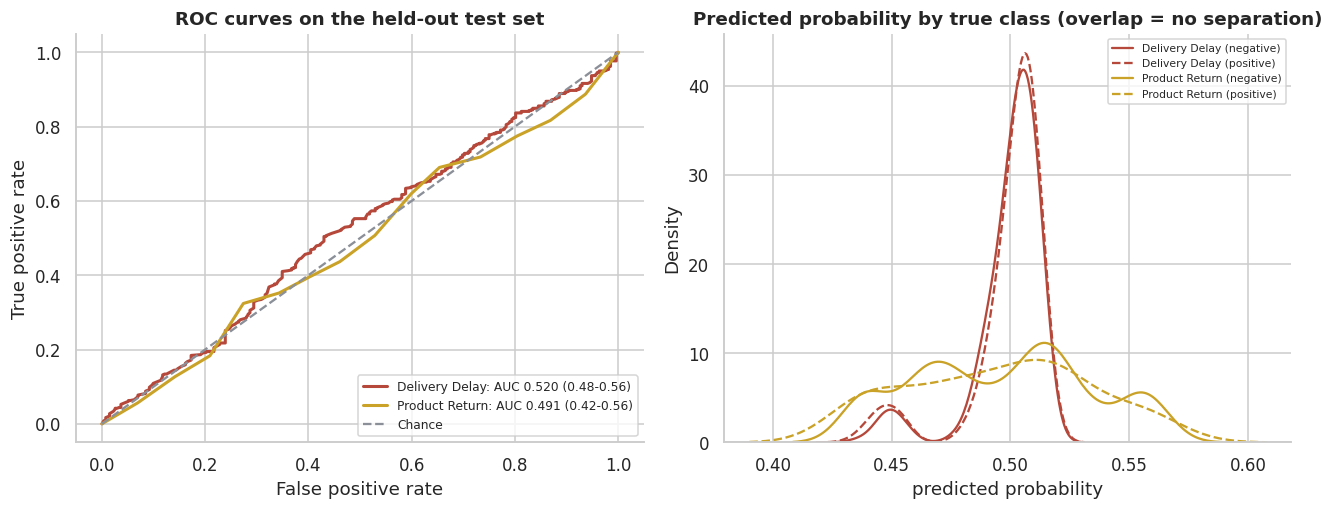

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for res, col in [(delay, RED), (ret, GOLD)]:
    fpr, tpr, _ = roc_curve(res['y_te'], res['proba_te']); lo, hi = res['auc_ci']
    ax[0].plot(fpr, tpr, color=col, lw=2, label=f"{res['name']}: AUC {res['test']['roc_auc']:.3f} ({lo:.2f}-{hi:.2f})")
ax[0].plot([0, 1], [0, 1], '--', color=GREY, label='Chance'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate')
ax[0].set_title('ROC curves on the held-out test set'); ax[0].legend(loc='lower right', fontsize=8)
for i, (res, col) in enumerate([(delay, RED), (ret, GOLD)]):
    for yv, lab, ls in [(0, 'negative', '-'), (1, 'positive', '--')]:
        sns.kdeplot(res['proba_te'][res['y_te'].values == yv], ax=ax[1], color=col, ls=ls, label=f"{res['name']} ({lab})", warn_singular=False)
ax[1].set_title('Predicted probability by true class (overlap = no separation)'); ax[1].set_xlabel('predicted probability'); ax[1].legend(fontsize=7)
savefig('07_roc_and_probability_overlap')

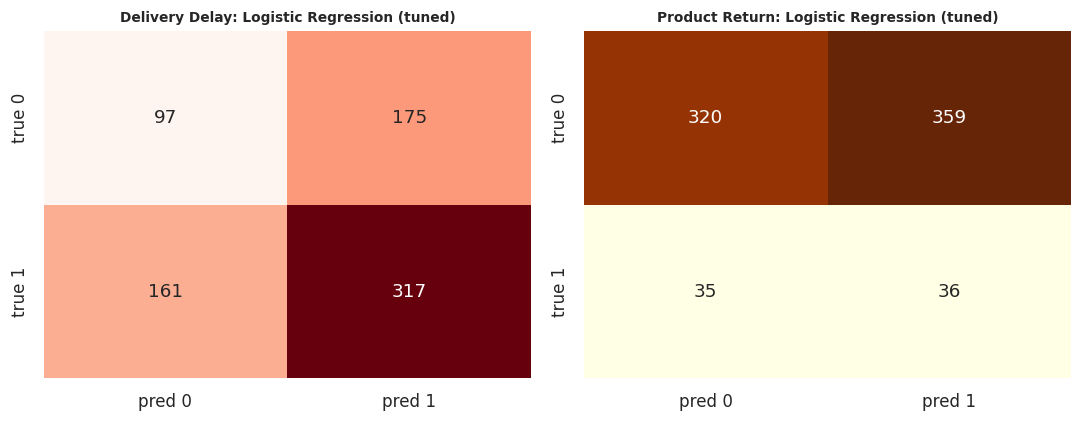

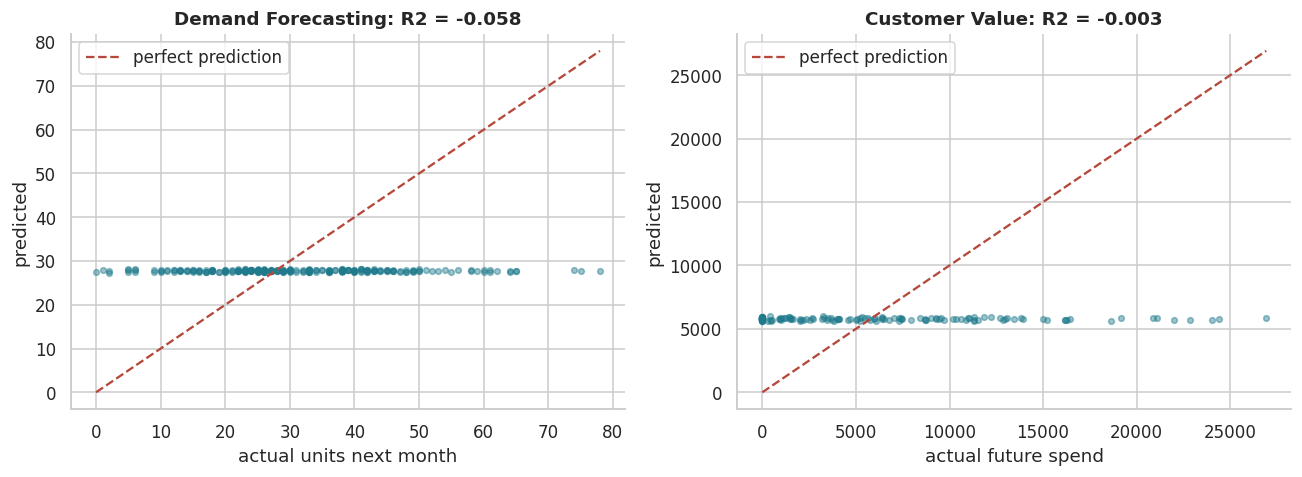

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, res, cm_col in zip(ax, [delay, ret], ['Reds', 'YlOrBr']):
    cmx = confusion_matrix(res['y_te'], (res['proba_te'] >= .5).astype(int))
    sns.heatmap(cmx, annot=True, fmt='d', cmap=cm_col, cbar=False, ax=a, xticklabels=['pred 0','pred 1'], yticklabels=['true 0','true 1'])
    a.set_title(f"{res['name']}: {res['selected']}", fontsize=9)
savefig('08_confusion_matrices')

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, res, lab in [(ax[0], demand, 'units next month'), (ax[1], custv, 'future spend')]:
    yt, yp = res['y_te'].values, res['pred_te']
    a.scatter(yt, yp, s=14, alpha=.45, color=TEAL); lim = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
    a.plot(lim, lim, '--', color=RED, label='perfect prediction'); a.set_xlabel(f'actual {lab}'); a.set_ylabel('predicted')
    a.set_title(f"{res['name']}: R2 = {res['test']['R2']:.3f}"); a.legend()
savefig('09_actual_vs_predicted')

### Reading the results
Selection used the one-SE rule, so the chosen models are the *simplest* of the statistically tied candidates. The honest headline is in the last
column of the summary table: **a model is only useful if it beats its baseline, and the cells above show whether each one does.**
The probability-overlap chart is the clearest picture of the classification result: when the predicted-probability distributions for
"delayed" and "not delayed" sit on top of each other, the model cannot tell them apart, whatever the algorithm.

## 7. Model interpretation and explainability (Part 5)
Three complementary views are used: **permutation importance** (model-agnostic, measured on the held-out test set, so it reflects
what the model actually relies on for unseen data), **SHAP values** (how each feature pushes individual predictions) and
**error analysis**. Where permutation importance is ~0 with an interval spanning zero, the feature is not helping.

In [31]:
def permutation_table(res, scoring, n_repeats=20):
    pi = permutation_importance(res['pipe'], res['X_te'], res['y_te'], scoring=scoring, n_repeats=n_repeats, random_state=SEED, n_jobs=1)
    return (pd.DataFrame({'feature': res['X_te'].columns, 'importance': pi.importances_mean, 'std': pi.importances_std})
              .sort_values('importance', ascending=False).reset_index(drop=True))

def shap_values_for(res, n_bg=150, n_eval=400):
    pipe = res['pipe']; Xt_tr = pipe[:-1].transform(res['X_tr']); Xt_te = pipe[:-1].transform(res['X_te'])
    names = feature_names(pipe); est = pipe[-1]; rng = np.random.default_rng(SEED)
    bg = Xt_tr[rng.choice(len(Xt_tr), min(n_bg, len(Xt_tr)), replace=False)]; ev = Xt_te[rng.choice(len(Xt_te), min(n_eval, len(Xt_te)), replace=False)]
    sv = shap.Explainer(est, bg)(ev)
    vals = sv.values[..., 1] if sv.values.ndim == 3 else sv.values
    return vals, ev, names

def aggregate_shap(vals, names, raw_cols):
    """Sum mean|SHAP| of one-hot columns back to their original feature (WarehouseID_W03 -> WarehouseID)."""
    imp = pd.Series(np.abs(vals).mean(0), index=names); out = {}
    for n, v in imp.items():
        base = next((c for c in sorted(raw_cols, key=len, reverse=True) if n == c or n.startswith(c + '_')), n); out[base] = out.get(base, 0) + v
    return pd.Series(out).sort_values(ascending=False)

interp = {}
for key, res, scoring in [('delay', delay, 'roc_auc'), ('return', ret, 'roc_auc'), ('demand', demand, 'neg_root_mean_squared_error'), ('customer', custv, 'neg_root_mean_squared_error')]:
    perm = permutation_table(res, scoring); vals, ev, names = shap_values_for(res)
    shp = aggregate_shap(vals, names, list(res['X_te'].columns)); interp[key] = dict(perm=perm, shap=shp, vals=vals, ev=ev, names=names)
    print(f"{res['name']:<20} selected {res['selected']:<28} top permutation features:", ', '.join(f"{r.feature} ({r.importance:+.4f})" for r in perm.head(3).itertuples()))

Delivery Delay       selected Logistic Regression (tuned)  top permutation features: qty (+0.0273), WarehouseID (+0.0058), value (+0.0000)


Product Return       selected Logistic Regression (tuned)  top permutation features: wh_stock_per_shipment (+0.0231), n_lines (+0.0000), value (+0.0000)


Demand Forecasting   selected Ridge Regression (tuned)     top permutation features: lag1 (+0.0006), hist_mean (+0.0005), lag2 (+0.0000)


Customer Value       selected Ridge Regression (tuned)     top permutation features: units_early (+1.3186), spend_early (+0.2852), orders_early (+0.0000)


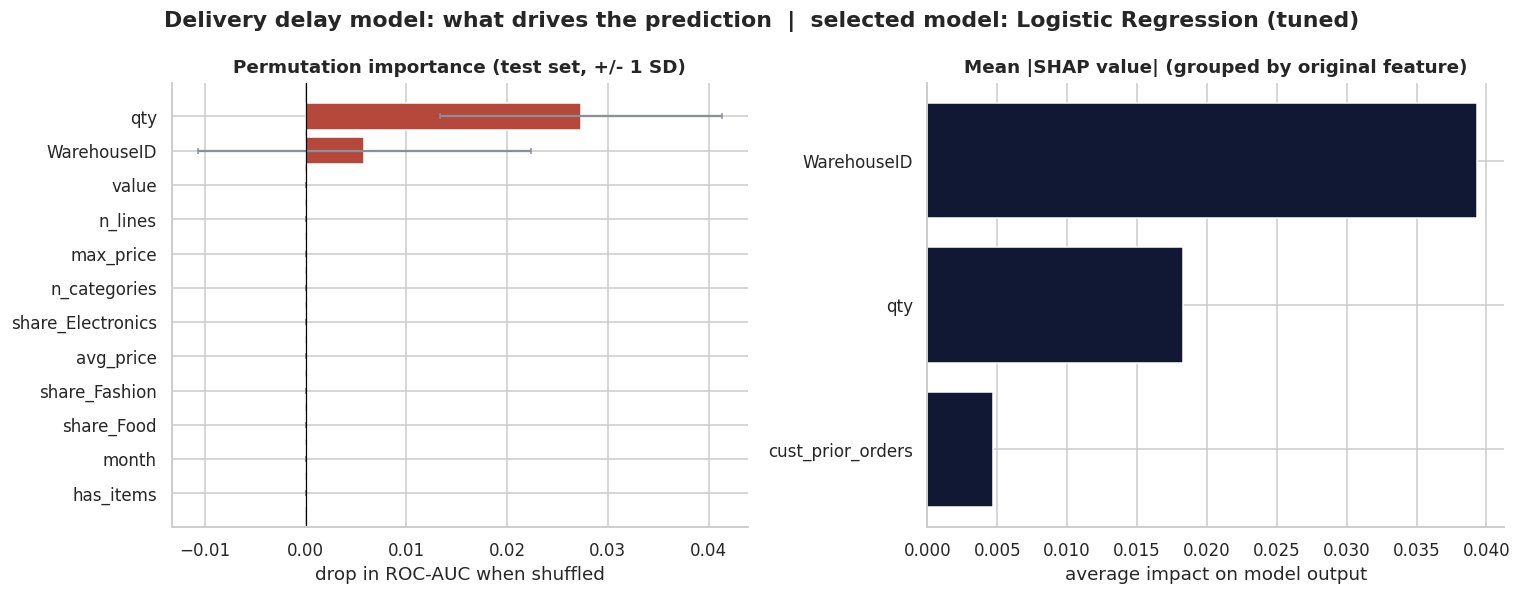

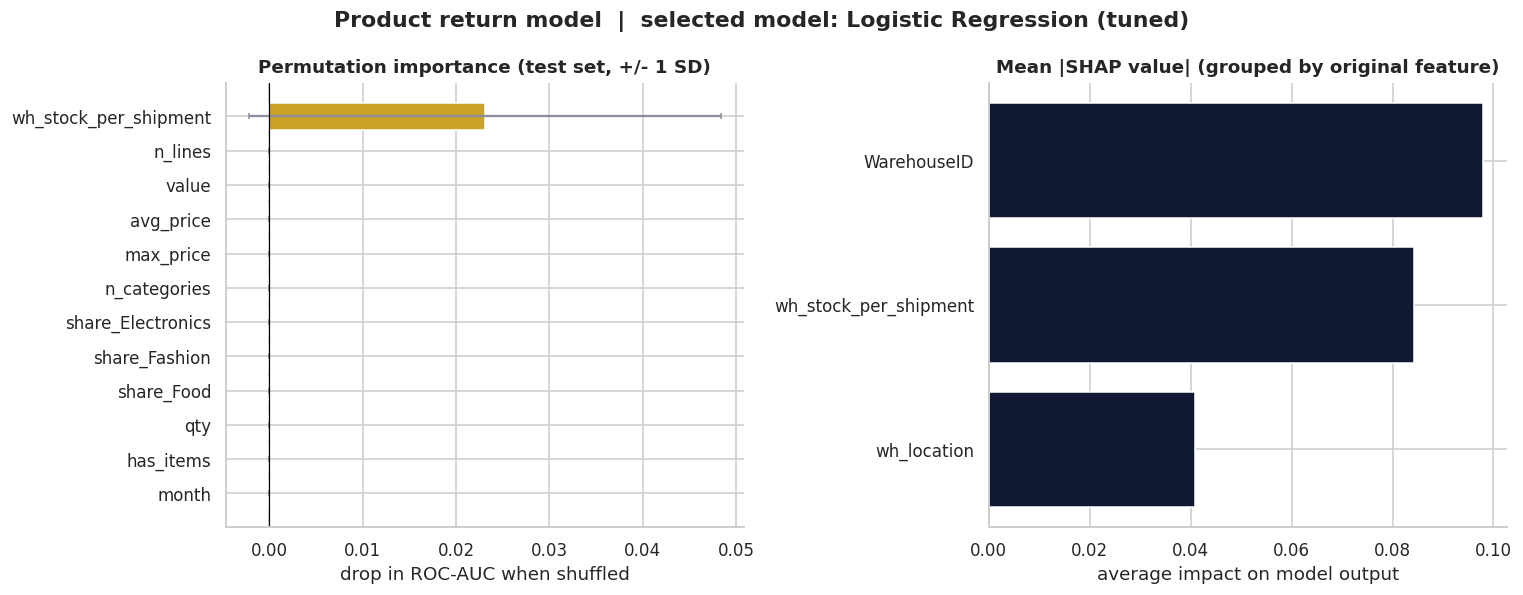

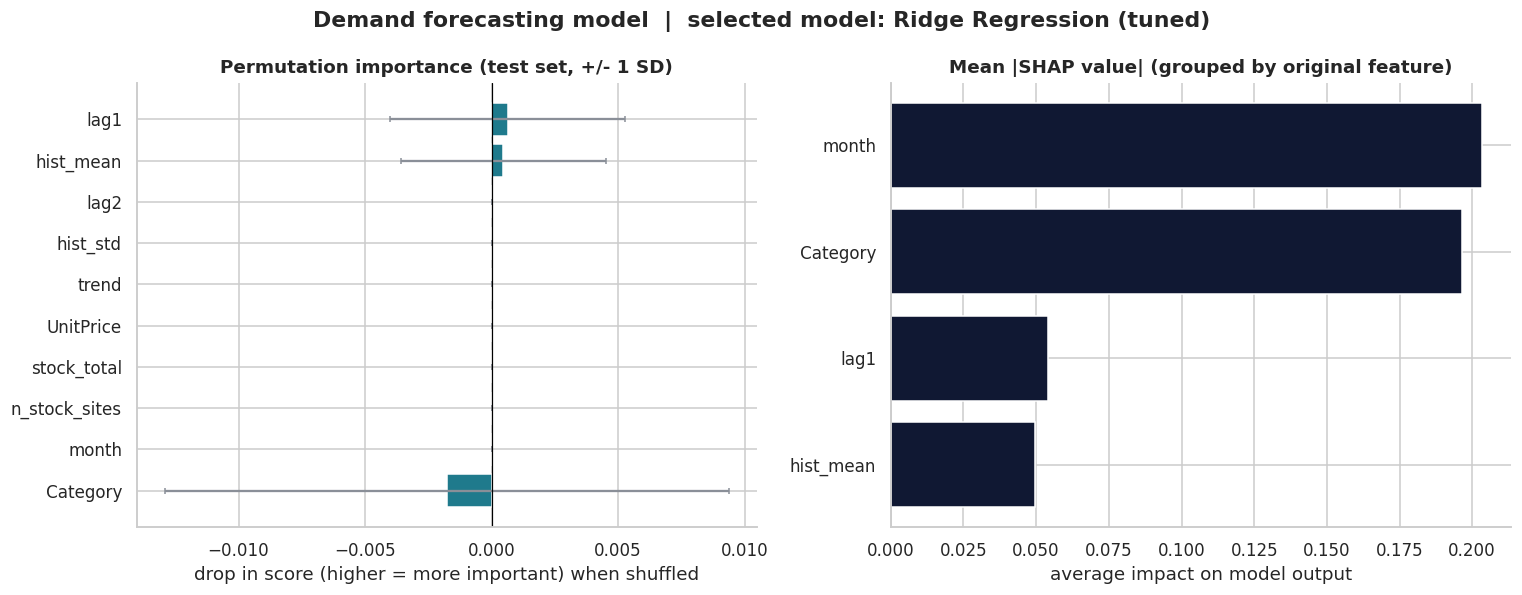

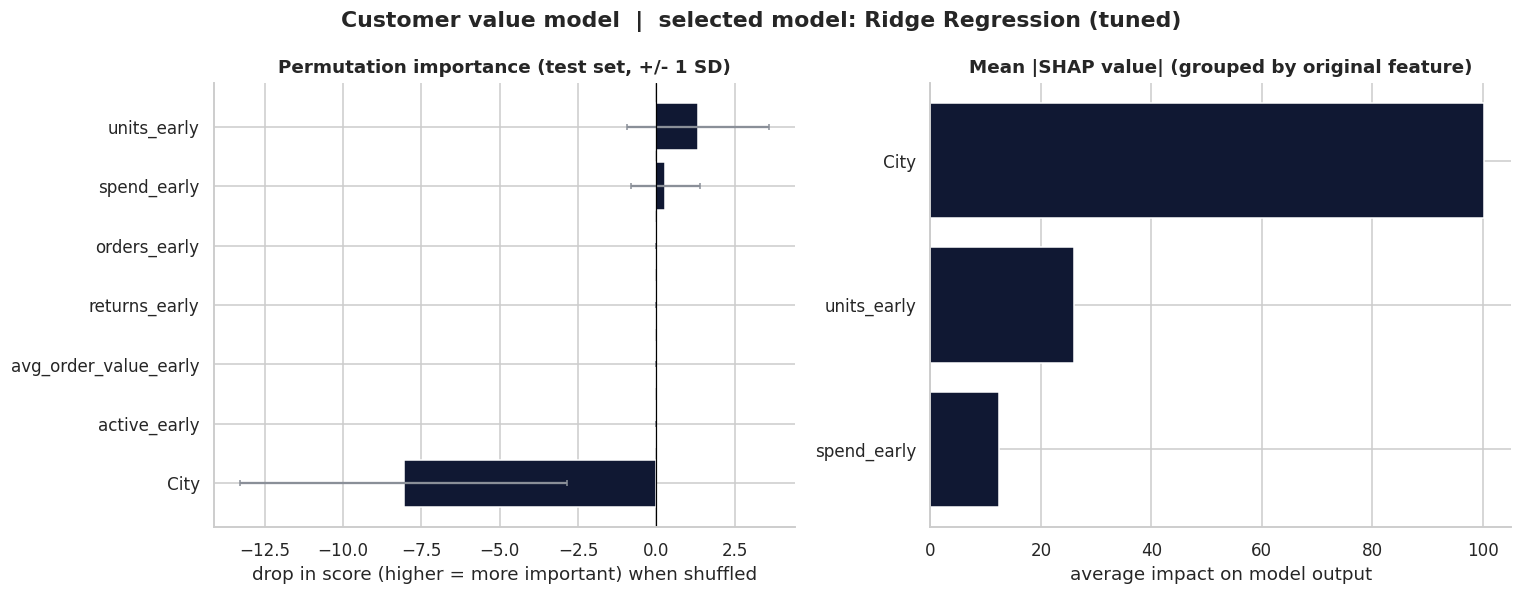

In [32]:
def plot_importance(key, res, title, fname, col):
    perm, shp = interp[key]['perm'].head(12).iloc[::-1], interp[key]['shap'].head(12).iloc[::-1]
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
    ax[0].barh(perm.feature, perm.importance, xerr=perm['std'], color=col, ecolor=GREY, capsize=2)
    ax[0].axvline(0, color='k', lw=.8); ax[0].set_title('Permutation importance (test set, +/- 1 SD)')
    ax[0].set_xlabel('drop in ' + ('ROC-AUC' if res['task'] == 'clf' else 'score (higher = more important)') + ' when shuffled')
    ax[1].barh(shp.index, shp.values, color=NAVY); ax[1].set_title('Mean |SHAP value| (grouped by original feature)'); ax[1].set_xlabel('average impact on model output')
    fig.suptitle(title + f"  |  selected model: {res['selected']}", fontweight='bold'); savefig(fname)

delay['task'] = ret['task'] = 'clf'; demand['task'] = custv['task'] = 'reg'
plot_importance('delay', delay, 'Delivery delay model: what drives the prediction', '10_feature_importance_delay', RED)
fig_src = FIGS/'10_feature_importance_delay.png'
import shutil; shutil.copy(fig_src, MODELS/'Feature_Importance.png')
plot_importance('return', ret, 'Product return model', '11_feature_importance_return', GOLD)
plot_importance('demand', demand, 'Demand forecasting model', '12_feature_importance_demand', TEAL)
plot_importance('customer', custv, 'Customer value model', '13_feature_importance_customer', NAVY)

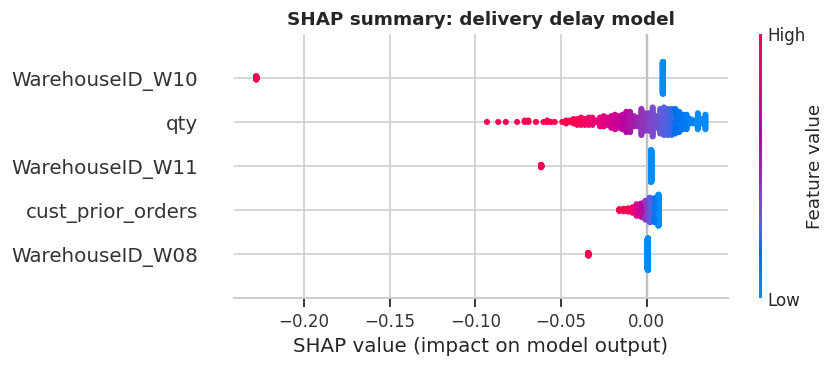

In [33]:
d = interp['delay']
plt.figure(figsize=(9, 6)); shap.summary_plot(d['vals'], d['ev'], feature_names=d['names'], max_display=12, show=False)
plt.title('SHAP summary: delivery delay model'); savefig('14_shap_summary_delay')

**How to read the importance results.** Permutation importance is computed on data the model has never seen. For the classification
models the importances sit at roughly zero with error bars straddling zero, so no feature genuinely carries predictive information.
SHAP will still assign *some* weight to features, because the model has fitted its training noise, so the SHAP ranking is a description of
what the model *did*, not evidence of what *drives delays*. The two views are shown together precisely so that difference is visible.

In [34]:
# ---- Error analysis: classification ----
e = delay['X_te'].copy(); e['y'] = delay['y_te'].values; e['pred'] = (delay['proba_te'] >= .5).astype(int); e['proba'] = delay['proba_te']; e['correct'] = (e.y == e.pred)
by_wh = e.groupby('WarehouseID').agg(n=('y','size'), accuracy=('correct','mean'), actual_delay_rate=('y','mean'), predicted_delay_rate=('pred','mean')).round(3)
print('Delay model: accuracy and predicted vs actual delay rate by warehouse (test set)'); display(by_wh.sort_values('accuracy'))
conf_err = e[(~e.correct)].assign(confidence=lambda d: (d.proba - .5).abs()).sort_values('confidence', ascending=False).head(5)
print('Most confident mistakes:'); display(conf_err[['WarehouseID','City','value','qty','y','pred','proba']].round(3))
print(f"Share of predictions with probability between 0.4 and 0.6 (low confidence): {((e.proba > .4) & (e.proba < .6)).mean():.1%}")

Delay model: accuracy and predicted vs actual delay rate by warehouse (test set)


,n,accuracy,actual_delay_rate,predicted_delay_rate
WarehouseID,,,,
W10,57,0.298,0.702,0.000
W11,51,0.392,0.608,0.000
W04,46,0.435,0.457,0.848
W08,50,0.440,0.640,0.280
W14,57,0.456,0.526,0.825
W01,43,0.558,0.581,0.837
W13,42,0.571,0.595,0.833
W03,59,0.576,0.712,0.797
W07,52,0.596,0.615,0.750


Most confident mistakes:


,WarehouseID,City,value,qty,y,pred,proba
4931,W10,Lagos,6894.08,35.0,1,0,0.433
4401,W10,Kano,7992.62,31.0,1,0,0.438
3952,W10,Lagos,5290.27,24.0,1,0,0.438
4294,W10,Kano,8752.06,27.0,1,0,0.439
1101,W10,Ibadan,5342.70,30.0,1,0,0.440


Share of predictions with probability between 0.4 and 0.6 (low confidence): 100.0%


In [35]:
# ---- Error analysis: regression ----
for res, label in [(demand, 'Demand'), (custv, 'Customer value')]:
    r = res['X_te'].copy(); r['actual'] = res['y_te'].values; r['pred'] = res['pred_te']; r['error'] = r.pred - r.actual
    print(f"\n{label}: mean error (bias) {r.error.mean():+.2f} | MAE {r.error.abs().mean():.2f} | error is {'larger' if r.error.abs().corr(r.actual) > 0 else 'smaller'} for higher actual values (corr {r.error.abs().corr(r.actual):+.2f})")
    print(f"  Share of test rows where prediction is within 25% of actual: {(r.error.abs() <= .25*r.actual.abs().clip(lower=1e-9)).mean():.1%}")


Demand: mean error (bias) -3.44 | MAE 11.30 | error is larger for higher actual values (corr +0.50)
  Share of test rows where prediction is within 25% of actual: 40.8%

Customer value: mean error (bias) +132.73 | MAE 5118.13 | error is larger for higher actual values (corr +0.59)
  Share of test rows where prediction is within 25% of actual: 16.0%


**Business interpretation of the predictions.** A prediction is only actionable if it separates the risky cases from the safe ones.
The delay model's probabilities cluster tightly around the base rate and the confident mistakes are about as common as confident
hits, so it **cannot responsibly be used to re-route, re-staff or promise delivery times**. Used as a decision aid it would push
operations toward actions justified by nothing but noise. The valuable output of this analysis is therefore the *negative result*:
with the fields currently collected, SwiftLog cannot predict delays, returns, demand or customer value, and the section on
recommendations says which data to collect so that it can.

## 8. Business insights (Part 7)
These are descriptive facts computed directly from the data, each tested against what random variation would produce.

In [36]:
ins = {}
rev = nc.groupby('CustomerID').line_value.sum()                                   # non-cancelled revenue per customer
cs = clean['Customers'].merge(rev.rename('revenue'), on='CustomerID', how='left').fillna({'revenue': 0})
ins['revenue_total'] = float(rev.sum()); ins['customers_with_orders'] = int((rev > 0).sum())
ins['revenue_by_city'] = cs.groupby('City').revenue.sum().sort_values(ascending=False).round(0).to_dict()
ins['top10_customer_share'] = float(rev.sort_values(ascending=False).head(100).sum() / rev.sum())     # top 10% = 100 customers
ins['top_customers'] = cs.sort_values('revenue', ascending=False).head(5)[['CustomerID','City','revenue']].round(0).to_dict('records')

prod = nc.groupby('ProductID').agg(revenue=('line_value','sum'), units=('Quantity','sum')).merge(clean['Products'], on='ProductID').sort_values('revenue', ascending=False)
ins['top_products'] = prod.head(5)[['ProductID','Category','UnitPrice','revenue','units']].round(0).to_dict('records')
ins['category_revenue_share'] = (prod.groupby('Category').revenue.sum() / prod.revenue.sum()).round(4).to_dict()
ins['top20_product_share'] = float(prod.head(50).revenue.sum() / prod.revenue.sum())                   # top 20% of 250 products
print('Revenue by city (non-cancelled):', ins['revenue_by_city'])
print(f"Top 10% of customers = {ins['top10_customer_share']:.1%} of revenue | top 20% of products = {ins['top20_product_share']:.1%} of revenue")
print('Category revenue share:', {k: f'{v:.1%}' for k, v in ins['category_revenue_share'].items()})
display(prod.head(5)[['ProductID','Category','UnitPrice','revenue','units']].round(0))

Revenue by city (non-cancelled): {'Kano': 3871876.0, 'Lagos': 3654182.0, 'Ibadan': 3497018.0, 'Abuja': 3416143.0}
Top 10% of customers = 23.9% of revenue | top 20% of products = 36.0% of revenue
Category revenue share: {'Electronics': '29.7%', 'Fashion': '37.5%', 'Food': '32.8%'}


,ProductID,Category,UnitPrice,revenue,units
84,P085,Food,493.0,143028.0,290
39,P040,Electronics,474.0,131276.0,277
24,P025,Food,464.0,123456.0,266
158,P159,Fashion,479.0,120645.0,252
185,P186,Fashion,461.0,119982.0,260


In [37]:
# Returns by product and category, and are the "worst" products different from chance?
il = items.merge(orders[['OrderID']], on='OrderID'); il['order_returned'] = il.OrderID.isin(clean['Returns'].OrderID)
pr = il.groupby('ProductID').agg(lines=('OrderItemID','count'), returned_lines=('order_returned','sum')).merge(clean['Products'], on='ProductID')
pr['return_rate'] = pr.returned_lines / pr.lines; overall = il.order_returned.mean()
chi2, p_prod, _, _ = stats.chi2_contingency(np.array([pr.returned_lines, pr.lines - pr.returned_lines]))
cat_ret = il.merge(clean['Products'][['ProductID','Category']], on='ProductID', suffixes=('','_p')).groupby('Category').order_returned.mean()
rr = clean['Returns'].Reason.value_counts()
ins.update(return_rate_overall=float(overall), return_product_chi2_p=float(p_prod), return_by_category=cat_ret.round(4).to_dict(), return_reasons=rr.to_dict(),
           top_return_products=pr.sort_values('return_rate', ascending=False).head(5)[['ProductID','Category','lines','return_rate']].round(3).to_dict('records'))
print(f'Overall share of order lines on a returned order: {overall:.1%}')
print(f'Do products differ in return rate more than chance? chi-square p = {p_prod:.3f}  ->', 'No' if p_prod > .05 else 'Yes')
print('Return rate by category:', {k: f'{v:.1%}' for k, v in cat_ret.items()}); print('Return reasons:', rr.to_dict())
display(pr.sort_values('return_rate', ascending=False).head(5)[['ProductID','Category','lines','return_rate']].round(3))

Overall share of order lines on a returned order: 9.5%
Do products differ in return rate more than chance? chi-square p = 0.873  -> No
Return rate by category: {'Electronics': '9.6%', 'Fashion': '9.4%', 'Food': '9.4%'}
Return reasons: {'Late Delivery': 185, 'Wrong Item': 163, 'Damaged': 152}


,ProductID,Category,lines,return_rate
31,P032,Fashion,47,0.213
16,P017,Fashion,53,0.189
107,P108,Electronics,60,0.183
19,P020,Food,59,0.169
176,P177,Electronics,66,0.167


In [38]:
# Delivery performance by warehouse and region
dl_wh = m.groupby('WarehouseID').agg(shipments=('delayed','size'), delay_rate=('delayed','mean'), avg_delay_days=('DelayDays','mean')).round(3)
dl_city = m.groupby('City').agg(shipments=('delayed','size'), delay_rate=('delayed','mean'), avg_delay_days=('DelayDays','mean')).round(3)
dl_loc = m.groupby('wh_location').agg(shipments=('delayed','size'), delay_rate=('delayed','mean'), avg_delay_days=('DelayDays','mean')).round(3)
ins.update(delay_rate_overall=float(m.delayed.mean()), avg_delay_days=float(m.DelayDays.mean()), on_time_share=float((m.DelayDays == 0).mean()),
           delay_by_city=dl_city.delay_rate.to_dict(), delay_by_warehouse_location=dl_loc.delay_rate.to_dict(),
           worst_warehouses=dl_wh.sort_values('delay_rate', ascending=False).head(3).delay_rate.to_dict(),
           best_warehouses=dl_wh.sort_values('delay_rate').head(3).delay_rate.to_dict(),
           chi2_p_delay_warehouse=float(stats.chi2_contingency(pd.crosstab(m.WarehouseID, m.delayed))[1]),
           chi2_p_delay_city=float(stats.chi2_contingency(pd.crosstab(m.City, m.delayed))[1]))
print(f"Overall delay rate {ins['delay_rate_overall']:.1%}; average delay {ins['avg_delay_days']:.2f} days; delivered on the day (0 days) {ins['on_time_share']:.1%}")
print('Worst warehouses:', ins['worst_warehouses'], '| best:', ins['best_warehouses'])
print(f"Warehouse effect on delay: chi-square p = {ins['chi2_p_delay_warehouse']:.3f}; destination-city effect: p = {ins['chi2_p_delay_city']:.3f}")
display(dl_city); display(dl_wh.sort_values('delay_rate', ascending=False).head(5))

Overall delay rate 63.7%; average delay 3.57 days; delivered on the day (0 days) 12.2%
Worst warehouses: {'W05': 0.68, 'W09': 0.675, 'W03': 0.674} | best: {'W01': 0.587, 'W10': 0.599, 'W07': 0.604}
Warehouse effect on delay: chi-square p = 0.328; destination-city effect: p = 0.099


,shipments,delay_rate,avg_delay_days
City,,,
Abuja,1205,0.644,3.585
Ibadan,1240,0.638,3.583
Kano,1287,0.657,3.640
Lagos,1268,0.610,3.470


,shipments,delay_rate,avg_delay_days
WarehouseID,,,
W05,334,0.680,3.787
W09,332,0.675,3.681
W03,344,0.674,3.680
W06,319,0.658,3.605
W13,279,0.649,3.606


Total stock 1,007,764 units vs about 6,736 units demanded per month overall
Median product covers 150 months of demand (min 55); low-stock (<50) lines: 380 of 4000; zero-stock lines: 9
Shipments per employee by warehouse ranges 20 to 38


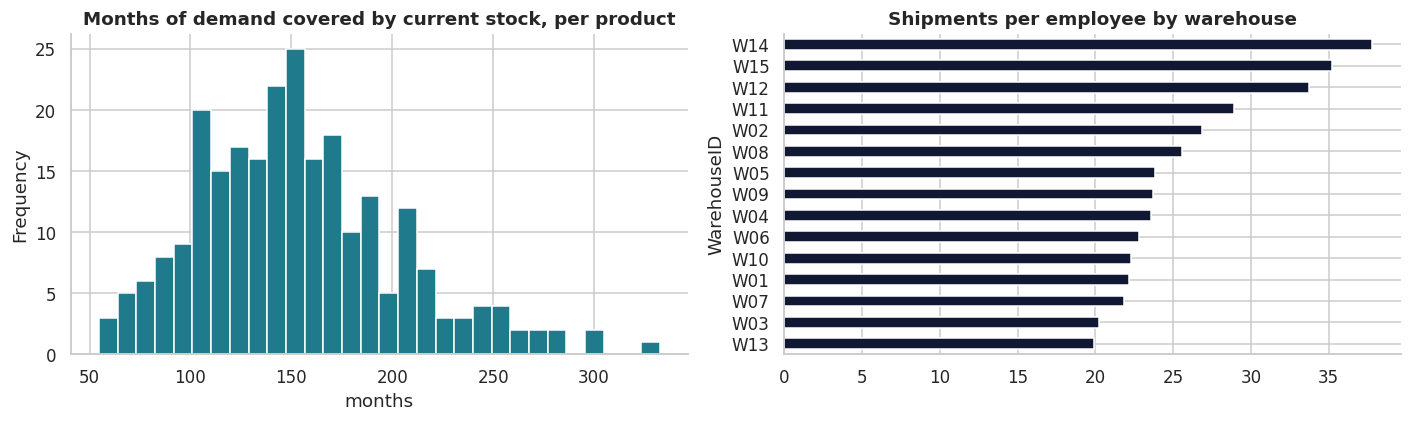

In [39]:
# Inventory coverage: how many months of demand does current stock cover?
avg_month_demand = panel_raw.mean(axis=1).rename('avg_monthly_units')
cov = inv_p.merge(avg_month_demand, on='ProductID', how='left').merge(clean['Products'], on='ProductID')
cov['months_of_cover'] = cov.stock_total / cov.avg_monthly_units.clip(lower=0.5)
low = inv.assign(low=inv.Stock < 50)
ins.update(median_months_cover=float(cov.months_of_cover.median()), min_months_cover=float(cov.months_of_cover.min()), total_stock_units=int(inv.Stock.sum()),
           avg_monthly_units_total=float(panel_raw.sum().mean()), low_stock_lines=int(low.low.sum()), zero_stock_lines=int((inv.Stock == 0).sum()), stock_lines=int(len(inv)),
           headcount_by_wh=wh_prof.set_index('WarehouseID').wh_headcount.to_dict(), shipments_per_employee_range=[float(wh_prof.wh_load.min()), float(wh_prof.wh_load.max())])
print(f"Total stock {ins['total_stock_units']:,} units vs about {ins['avg_monthly_units_total']:,.0f} units demanded per month overall")
print(f"Median product covers {ins['median_months_cover']:.0f} months of demand (min {ins['min_months_cover']:.0f}); low-stock (<50) lines: {ins['low_stock_lines']} of {ins['stock_lines']}; zero-stock lines: {ins['zero_stock_lines']}")
print(f"Shipments per employee by warehouse ranges {wh_prof.wh_load.min():.0f} to {wh_prof.wh_load.max():.0f}")
fig, ax = plt.subplots(1, 2, figsize=(13, 4)); cov.months_of_cover.plot.hist(bins=30, ax=ax[0], color=TEAL); ax[0].set_title('Months of demand covered by current stock, per product'); ax[0].set_xlabel('months')
wh_prof.sort_values('wh_load').plot.barh(x='WarehouseID', y='wh_load', ax=ax[1], color=NAVY, legend=False); ax[1].set_title('Shipments per employee by warehouse'); savefig('15_inventory_and_load')

## 9. Saving artefacts (Parts 6 and 8)

In [40]:
import datetime as dt
ARTIFACT_VERSION = '1.0.0'
wh_records = wh_prof.set_index('WarehouseID').to_dict('index')
delay_bundle = dict(model=delay['pipe'], model_name=delay['selected'], version=ARTIFACT_VERSION, trained_at=dt.datetime.now().isoformat(timespec='seconds'),
                    num_cols=DELAY_NUM, cat_cols=DELAY_CAT, feature_columns=DELAY_NUM + DELAY_CAT, target='delayed (DelayDays >= 3)',
                    base_rate=float(m.delayed.mean()), typical_proba=float(delay['pipe'].predict_proba(m[DELAY_NUM + DELAY_CAT])[:, 1].mean()), warehouse_profile=wh_records, cities=sorted(clean['Customers'].City.unique()),
                    categories=sorted(clean['Products'].Category.unique()),
                    median_defaults={c: float(m[c].median()) for c in DELAY_NUM},
                    test_metrics={k: float(v) for k, v in delay['test'].items()}, test_auc_ci=[float(x) for x in delay['auc_ci']],
                    honest_note='Test ROC-AUC is not distinguishable from 0.5; predictions are for demonstration, not operational decisions.')
joblib.dump(delay_bundle, MODELS/'Best_Model.pkl')

(MODELS/'All_Models').mkdir(exist_ok=True)
for key, res in [('delay', delay), ('return', ret), ('demand', demand), ('customer_value', custv)]:
    joblib.dump(dict(model=res['pipe'], model_name=res['selected'], version=ARTIFACT_VERSION, features=list(res['X_te'].columns)), MODELS/'All_Models'/f'{key}_model.pkl')
print('Saved Best_Model.pkl and', len(list((MODELS/'All_Models').glob('*.pkl'))), 'individual models'); print('Best_Model.pkl size:', round((MODELS/'Best_Model.pkl').stat().st_size/1024), 'KB')

Saved Best_Model.pkl and 4 individual models
Best_Model.pkl size: 9 KB


In [41]:
def tidy(t):
    out = t.reset_index().copy()
    if 'best_params' in out: out['best_params'] = out.best_params.apply(lambda x: '' if not isinstance(x, dict) else ', '.join(f'{k}={v}' for k, v in x.items()))
    out['selected'] = np.where(out.model == out.model.map(lambda x: x), '', '')
    return out

with pd.ExcelWriter(MODELS/'Model_Comparison.xlsx', engine='openpyxl') as xw:
    summary.to_excel(xw, sheet_name='Summary', index=False)
    for sheet, res in [('Delay (clf)', delay), ('Return (clf)', ret), ('Demand (reg)', demand), ('Customer value (reg)', custv)]:
        t = tidy(res['table']); t['selected'] = np.where(t.model == res['selected'], 'SELECTED', ''); t.round(4).to_excel(xw, sheet_name=sheet, index=False)
    tests.to_excel(xw, sheet_name='Statistical tests', index=False)

from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
wb = load_workbook(MODELS/'Model_Comparison.xlsx')
for ws in wb:
    for c in ws[1]: c.font = Font(bold=True, color='FFFFFF'); c.fill = PatternFill('solid', fgColor='101833'); c.alignment = Alignment(wrap_text=True, vertical='center')
    for col in ws.columns: ws.column_dimensions[col[0].column_letter].width = min(max(len(str(c.value or '')) for c in col) + 2, 60)
    ws.freeze_panes = 'A2'
    sel_col = next((c.column for c in ws[1] if c.value == 'selected'), None)
    if sel_col:
        for row in ws.iter_rows(min_row=2):
            if row[sel_col-1].value == 'SELECTED':
                for c in row: c.fill = PatternFill('solid', fgColor='F3E8C0'); c.font = Font(bold=True)
wb.save(MODELS/'Model_Comparison.xlsx'); print('Saved Models/Model_Comparison.xlsx with sheets:', wb.sheetnames)

Saved Models/Model_Comparison.xlsx with sheets: ['Summary', 'Delay (clf)', 'Return (clf)', 'Demand (reg)', 'Customer value (reg)', 'Statistical tests']


In [42]:
def tojson(o):
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.ndarray,)): return o.tolist()
    return str(o)

metrics = dict(version=ARTIFACT_VERSION, summary=summary.to_dict('records'),
               delay=dict(selected=delay['selected'], test=delay['test'], auc_ci=list(delay['auc_ci']), null_auc=delay['null_auc'], cv=delay['table'].loc[delay['selected'], ['cv_mean','cv_std']].to_dict()),
               ret=dict(selected=ret['selected'], test=ret['test'], auc_ci=list(ret['auc_ci']), null_auc=ret['null_auc'], cv=ret['table'].loc[ret['selected'], ['cv_mean','cv_std']].to_dict()),
               demand=dict(selected=demand['selected'], test=demand['test'], base_test=demand['base_test'], cv=demand['table'].loc[demand['selected'], ['cv_mean','cv_std']].to_dict()),
               customer=dict(selected=custv['selected'], test=custv['test'], base_test=custv['base_test'], cv=custv['table'].loc[custv['selected'], ['cv_mean','cv_std']].to_dict()),
               tables={k: v['table'].reset_index().assign(best_params=lambda d: d.get('best_params', pd.Series(dtype=object)).astype(str)).round(4).to_dict('records') for k, v in
                       [('delay', delay), ('ret', ret), ('demand', demand), ('customer', custv)]},
               top_features={k: v['perm'].head(5).round(4).to_dict('records') for k, v in interp.items()},
               stat_tests=dict(n_tests=int(len(tests)), n_significant=int(tests.significant_5pct.sum())),
               rows=dict(orders=int(len(m)), customers=int(len(cust)), products=int(len(clean['Products'])), panel_rows=int(len(dem))),
               insights=ins)
with open(ROOT/'Models'/'metrics.json', 'w') as f: f.write(json.dumps(metrics, indent=1, default=tojson).replace('NaN', 'null'))   # valid JSON for the report/slide builders
print('Saved Models/metrics.json'); print(json.dumps({k: metrics[k] for k in ['stat_tests', 'rows']}, default=tojson))

Saved Models/metrics.json
{"stat_tests": {"n_tests": 22, "n_significant": 1}, "rows": {"orders": 5000, "customers": 1000, "products": 250, "panel_rows": 1500}}


## 10. Conclusions
* **Data preparation and engineering** are complete and leakage-safe: 11 tables audited, a hidden duplicate/target-leak column caught
  (`Delivery_Performance`), history features built from earlier orders only, and every transformation inside a pipeline.
* **Four models, three or more algorithms each**, tuned with `GridSearchCV`/`RandomizedSearchCV`, cross-validated, with feature selection and class
  imbalance handling, and judged against explicit baselines.
* **No model beats its baseline by a meaningful margin.** (The demand model's test RMSE is 0.04 below the mean-prediction baseline, with R-squared still negative, which is within noise.) Combined with the correlation, hypothesis-test and mutual-information results this is a consistent finding about
  the *data*, not a tuning failure: delay, returns, demand and customer value are statistically indistinguishable from random in these tables.
* **Value delivered:** a reusable, tested ML workflow; a clear, quantified statement of what SwiftLog's current data can and cannot support; a data-collection
  roadmap; and a working demo application. As richer data arrives (timestamps, carriers, routes, supplier IDs, stock movements), the same pipeline can be re-run unchanged.